# 01 - Exploratory Data Analysis

## Table of Contents

- [01 - Exploratory Data Analysis](#01---Exploratory-Data-Analysis)
  - [Purpose](#Purpose)
  - [Summary](#Summary)
    - [Data Cleaning Process](#Data-Cleaning-Process)
    - [Findings](#Findings)
  - [Read in packages](#Read-in-packages)
  - [Read in data](#Read-in-data)
    - [Read in ArcGIS data](#Read-in-ArcGIS-data)
    - [Read in Smart Project Data](#Read-in-Smart-Project-Data)
  - [Data Cleaning](#Data-Cleaning)
    - [Columns check](#Columns-check)
    - [Removing NA rows/columns](#Removing-NA-rows/columns)
    - [Joining IDAX data to SDOT GIS data](#Joining-IDAX-data-to-SDOT-GIS-data)
    - [Removing 6pm onwards](#Removing-6pm-onwards)
    - [Selecting loading zone space type](#Selecting-loading-zone-space-type)
    - [Creating illgal parking](#Creating-illgal-parking)
    - [Join Weather Data](#Join-Weather-Data)
  - [Data Analysis](#Data-Analysis)
    - [Illegally Parked](#Illegally-Parked)
      - [Count](#Count)
      - [By Unitdesc](#By-Unitdesc)
        - [Illgally parked per zone by park by month](#Illgally-parked-per-zone-by-park-by-month)
        - [Illgally parked per zone by park start hour](#Illgally-parked-per-zone-by-park-start-hour)
        - [Illgally parked by zone by day of week](#Illgally-parked-by-zone-by-day-of-week)
        - [activity_type by unitdesc](#activity_type-by-unitdesc)
      - [Rain/precipitation](#Rain/precipitation)
        - [Rain vs Illegally Parked](#Rain-vs-Illegally-Parked)
        - [Duration vs Rain](#Duration-vs-Rain)
      - [temperature](#temperature)
        - [Duration & Temperature](#Duration-&-Temperature)
      - [duration](#duration)
        - [duration of illgally parked car vs not](#duration-of-illgally-parked-car-vs-not)
        - [Duration vs Precipitation](#Duration-vs-Precipitation)
        - [Duration vs Activity Type](#Duration-vs-Activity-Type)
      - [Day of week](#Day-of-week)
        - [Day of Week vs Duration](#Day-of-Week-vs-Duration)
      - [passenger_inout, driver_out](#passenger_inout,-driver_out)
      - [cvlz_permit_vid](#cvlz_permit_vid)
      - [Car Body Type](#Car-Body-Type)
    - [Looking at Car Body Type](#Looking-at-Car-Body-Type)
  - [GIS Data Analysis](#GIS-Data-Analysis)
    - [Limitations](#Limitations)
      - [Finding distance between each zones](#Finding-distance-between-each-zones)
        - [by converting longitude and latitude](#by-converting-longitude-and-latitude)
        - [by openstreetmap and finding shortest walking distnace](#by-openstreetmap-and-finding-shortest-walking-distnace)

## Purpose 
This notebook explores two datasets: ArcGIS data from the City of Seattle and curbside parking data from the Seattle Smart project, run by the Urban Freight Lab at the University of Washington. The project's goal is to use curbside data to optimize the placement of parking enforcement officers to maximize the number of parking tickets issued. The analysis therefore focuses on features that may be related to illegal parking in loading zones.

## Summary

### Data Cleaning Process

### Findings 

## Read in packages

In [ ]:
# read in packages
import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt
import requests
import pandas as pd
import requests
import numpy as np

## Read in data 

### Read in ArcGIS data

In [ ]:
# read in curb spaces from the Seattle ArcGIS API (paged, server returns max 2000 rows per request)
import pandas as pd

URL = ("https://services.arcgis.com/ZOyb2t4B0UYuYNYH/arcgis/rest/services/"
       "Curb_Space_Categories/FeatureServer/6/query")

# rows per request; the server won't return more than its max at once
PAGE_SIZE = 2000

pages = []
offset = 0
while True:
    r = requests.get(URL, params={
        "where": "1=1",
        "outFields": "*", # return all columns
        "f": "geojson",  # response format: GeoJSON
        "orderByFields": "OBJECTID",
        "resultOffset": offset, # skip this many rows (start of this page)
        "resultRecordCount": PAGE_SIZE, # how many rows to return in this page
    }, timeout=60)
    r.raise_for_status()
    data = r.json()
    if "error" in data:
        raise RuntimeError(data["error"])
    if not data["features"]:
        break
    pages.append(gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326"))
    offset += PAGE_SIZE

gis_curb_spaces = pd.concat(pages, ignore_index=True)
print(gis_curb_spaces.shape)

# Coordinate Reference System
print(gis_curb_spaces.crs) 
# CRS defines how the numbers in geometry map to real locations on earth

print(gis_curb_spaces.columns.tolist())

gis_curb_spaces.head()

(40516, 28)
EPSG:4326
['geometry', 'OBJECTID', 'BLOCKID', 'BLOCK_ST', 'BLOCK_END', 'WIDTH_OFFSET', 'GEOBASYS', 'SPACELENGTH', 'SPACETYPE', 'SPACETYPEDESC', 'TIME_LIMIT', 'SPACE_NB', 'CATEGORY', 'SIDE', 'CURRENT_STATUS', 'ELMNTKEY', 'SPACEKEY', 'SEGKEY', 'PRIMARYDISTRICTCD', 'SECONDARYDISTRICTCD', 'OVERRIDEYN', 'OVERRIDECOMMENT', 'PAIDAREA', 'SUBAREA', 'UNIQUEID', 'STOPSTATUS', 'STOP_STATUS_DESCRIPTION', 'Shape__Length']


,geometry,OBJECTID,BLOCKID,BLOCK_ST,BLOCK_END,WIDTH_OFFSET,GEOBASYS,SPACELENGTH,SPACETYPE,SPACETYPEDESC,...,PRIMARYDISTRICTCD,SECONDARYDISTRICTCD,OVERRIDEYN,OVERRIDECOMMENT,PAIDAREA,SUBAREA,UNIQUEID,STOPSTATUS,STOP_STATUS_DESCRIPTION,Shape__Length
0,"LINESTRING (-122.35812 47.62, -122.35812 47.62...",689116,W01-02,82.0,101.0,18,None,19,PS,PAY STATION,...,DISTRICT7,,N,None,Uptown,NaN,None,,NaN,18.985333
1,"LINESTRING (-122.3555 47.6237, -122.3555 47.62...",689117,N01-05,157.0,175.0,22,None,18,PS,PAY STATION,...,DISTRICT7,,N,None,Uptown,NaN,None,,NaN,17.986949
2,"LINESTRING (-122.34818 47.61425, -122.3482 47....",689118,01-24,94.5,102.0,30,None,8,CLR,CLEARANCE,...,DISTRICT7,,N,None,Belltown,North,None,,NaN,7.492422
3,"LINESTRING (-122.31807 47.616, -122.31807 47.6...",689119,E11-16,271.0,276.0,-24,None,5,CLR,CLEARANCE,...,DISTRICT3,,N,None,Capitol Hill,South,None,,NaN,4.989168
4,"LINESTRING (-122.31675 47.65696, -122.31675 47...",689120,NE11-41,32.0,42.0,14,None,10,TAZ,TOW AWAY ZONE,...,DISTRICT4,,N,None,University District,Edge,None,,NaN,9.979725


### Read in Smart Project Data

In [ ]:
# read in 3 rounds of data from Smart Project
idax_1 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 1 Data Collection.csv')
idax_2 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 2 Data Collection.csv')
idax_3 = pd.read_csv('../data/SMART Project Data/dot_87983_DS1/IDAX Round 3 Data Collection.csv')

print(idax_1.head())
print(idax_2.head())
print(idax_3.head())

   Event_NB  IDAX_Site_NB  ufl_block_id ufl_blockface_id  \
0         1             1            87             87SW   
1         2             1            87             87SW   
2         3             1            87             87SW   
3         4             1            87             87SW   
4         5             1            87             87SW   

                                 unitdesc BLOCK_ID  ELMNTKEY SPACETYPE  \
0  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
1  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
2  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713       PLZ   
3  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   
4  2ND AVE BETWEEN BELL ST AND BATTERY ST    02-23     25713        PS   

  SPACE_NB Concatenated_SPACE_NB  ... activity_type commercial_logo  \
0      -12              02-23-12  ...       Private          <null>   
1      -04              02-23-04  ...       Private 

In [ ]:
# shape of the datasets

print("idax_1: ", idax_1.shape)
print("idax_2: ", idax_2.shape)
print("idax_3: ", idax_3.shape)

# given the size of the data, deep learning models (neural network) is not possible.

idax_1:  (8182, 30)
idax_2:  (384, 22)
idax_3:  (263, 15)


## Data Cleaning
Given the small size of the idax_2 and 3 and the complications from inconsistent variables/columns, I suggest dropping IDAX 2 and 3 in our analysis and model. Given how small the rows are it wouldn't matter too much. 

### Columns check 
Not all columns exist in all 3 datasets

In [ ]:
dfs = {"idax_1": idax_1, "idax_2": idax_2, "idax_3": idax_3}
cols = {name: set(df.columns) for name, df in dfs.items()}

all_cols = sorted(set.union(*cols.values()))
idax_columns_df_all = pd.DataFrame({name: [c in cols[name] for c in all_cols] for name in dfs}, index=all_cols)
idax_columns_df_all

,idax_1,idax_2,idax_3
BLOCK_ID,True,True,True
CVLZ_permit_vid,True,False,False
Concatenated_PRIMARY_SPACE_NB,False,True,False
Concatenated_SECONDARY_SPACE_NB,False,True,False
Concatenated_SPACE_NB,True,False,False
Curbside_Location,False,True,False
Date,True,True,True
Dwell,False,True,False
ELMNTKEY,True,True,True
Event_NB,True,True,False


In [ ]:
# show just the columns that are available in all 3 in presence
idax_columns_df_all[idax_columns_df_all.all(axis=1)]

,idax_1,idax_2,idax_3
BLOCK_ID,True,True,True
Date,True,True,True
ELMNTKEY,True,True,True
SPACETYPE,True,True,True
park_end,True,True,True
park_start,True,True,True
total_duration,True,True,True
ufl_block_id,True,True,True
ufl_blockface_id,True,True,True
unitdesc,True,True,True


### Removing NA rows/columns

In [ ]:
df = idax_1.replace('<null>', pd.NA)

na_counts = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
na_counts.sort_values("missing", ascending=False)

,missing,percent
Unnamed: 27,8182,100.0
Unnamed: 28,8181,100.0
Unnamed: 29,8181,100.0
permit_type,7439,90.9
commercial_logo,6888,84.2
driver_outtime,4603,56.3
driverout_end,4364,53.3
driverout_start,4244,51.9
total_duration,662,8.1
park_end,408,5.0


In [ ]:
# should drop columns with more than 50% missing data from idax_1
# should also drop rows where total_duration is missing or where park_start, park_missing data is missing as this is a required data 

# replace the text '<null>' with real missing values
idax_1_clean = idax_1.replace('<null>', pd.NA)

# 1. drop columns with more than 50% missing
missing_share = idax_1_clean.isna().mean()
dropped_cols = missing_share[missing_share > 0.5].index.tolist()
print("dropping columns:", dropped_cols)
idax_1_clean = idax_1_clean.drop(columns=dropped_cols)

# 2. drop rows missing any of the required fields
required = ['total_duration', 'park_start', 'park_end']
before = len(idax_1_clean)
idax_1_clean = idax_1_clean.dropna(subset=required)
print(f"dropped {before - len(idax_1_clean)} rows; {len(idax_1_clean)} remain")


dropping columns: ['driverout_start', 'driverout_end', 'driver_outtime', 'commercial_logo', 'permit_type', 'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29']
dropped 662 rows; 7520 remain


### Joining IDAX data to SDOT GIS data

In [ ]:
# join idax_1 to curbspaces on blockid and see paid area to see what paid area are in idax_1
gis_block_lookup = gis_curb_spaces[['BLOCKID', 'PAIDAREA']].dropna().drop_duplicates()

idax_1_area = idax_1.merge(gis_block_lookup, left_on='BLOCK_ID', right_on='BLOCKID', how='left')

print(idax_1.shape, idax_1_area.shape)  # same number of rows = no duplicates
idax_1_area['PAIDAREA'].value_counts(dropna=False)

(8182, 30) (8182, 32)


PAIDAREA
Denny Triangle    3812
Belltown          3766
NaN                604
Name: count, dtype: int64

In [ ]:
# check the paidarea blockid that is missing 
idax_1_area[idax_1_area['PAIDAREA'].isna()]['BLOCK_ID'].unique()

<StringArray>
['53']
Length: 1, dtype: str

In [ ]:
x = idax_1[idax_1['BLOCK_ID'] == '53']
print(len(x))
print(x['unitdesc'].unique())        # street description
print(x['ELMNTKEY'].unique())        # street segment ID
print(x['ufl_block_id'].unique())    # note: also 53

# based on google map this is Danny Triangle

604
<StringArray>
['7TH AVE BETWEEN BLANCHARD ST AND BELL ST']
Length: 1, dtype: str
[53433]
[53]


In [ ]:
gis_curb_spaces[gis_curb_spaces['ELMNTKEY'].isin(x['ELMNTKEY'].unique())][['BLOCKID', 'PAIDAREA', 'ELMNTKEY']].drop_duplicates()
# so this should match but the BLOCKID between idax_1 and curb_space data is different 

,BLOCKID,PAIDAREA,ELMNTKEY
5683,07-22,Denny Triangle,53433


In [ ]:
gis_curb_spaces[gis_curb_spaces['BLOCKID'].astype(str).str.contains(r'^53|-53$')]['BLOCKID'].unique()
# none of these matches 


<StringArray>
['NW22-53', 'NWBL-53', 'NWTN-53']
Length: 3, dtype: str

In [ ]:
m = idax_1[idax_1['BLOCK_ID'] != '53']

print(m['ELMNTKEY'].isin(gis_curb_spaces['ELMNTKEY']).mean())   # share of IDAX rows whose ELMNTKEY exists in curb_spaces

keys_per_block = gis_curb_spaces.groupby('ELMNTKEY')['BLOCKID'].nunique()
print((keys_per_block[m['ELMNTKEY'].unique()] > 1).sum())   # keys mapping to more than one block

1.0
0


In [ ]:
# how many idax_1 rows have an ELMNTKEY that exists in curb_spaces?
ok = idax_1_clean['ELMNTKEY'].isin(gis_curb_spaces['ELMNTKEY'])
print("rows:", len(idax_1_clean))
print("matched:", ok.sum(), "| unmatched:", (~ok).sum(), "| null keys:", idax_1_clean['ELMNTKEY'].isna().sum())

# distinct keys
print("distinct ELMNTKEY:", idax_1_clean['ELMNTKEY'].nunique(),
      "| matched:", idax_1_clean.loc[ok, 'ELMNTKEY'].nunique())
print("unmatched keys:", sorted(idax_1_clean.loc[~ok, 'ELMNTKEY'].dropna().unique()))

# left join on ELMNTKEY (overwrites the earlier BLOCK_ID-based idax_1_area)
elmnt_area = gis_curb_spaces[['ELMNTKEY', 'BLOCKID', 'PAIDAREA']].dropna().drop_duplicates()
idax_1_area = idax_1_clean.merge(elmnt_area, on='ELMNTKEY', how='left')

print("rows after merge:", len(idax_1_area), "vs", len(idax_1_clean))     # same = no duplicates
print("PAIDAREA missing:", idax_1_area['PAIDAREA'].isna().sum())
print(idax_1_area['PAIDAREA'].value_counts(dropna=False))

# where does BLOCK_ID disagree with the curb block?
print((idax_1_area['BLOCK_ID'] != idax_1_area['BLOCKID']).sum())
idax_1_area[idax_1_area['BLOCK_ID'] != idax_1_area['BLOCKID']][['BLOCK_ID', 'BLOCKID']].drop_duplicates()


rows: 7520
matched: 7520 | unmatched: 0 | null keys: 0
distinct ELMNTKEY: 28 | matched: 28
unmatched keys: []
rows after merge: 7520 vs 7520
PAIDAREA missing: 0
PAIDAREA
Denny Triangle    4139
Belltown          3381
Name: count, dtype: int64
574


,BLOCK_ID,BLOCKID
1105,53,07-22


In [ ]:
# checking for missing data again
df = idax_1_area.replace('<null>', pd.NA)

na_counts = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(1),
})
na_counts.sort_values("missing", ascending=False)

,missing,percent
passenger_inout,5,0.1
Event_NB,0,0.0
ufl_block_id,0,0.0
IDAX_Site_NB,0,0.0
unitdesc,0,0.0
BLOCK_ID,0,0.0
ELMNTKEY,0,0.0
ufl_blockface_id,0,0.0
SPACETYPE,0,0.0
SPACE_NB,0,0.0


### Removing 6pm onwards

In [174]:
pd.to_timedelta(idax_1_area['park_start']).min()   # 0 days 07:00:31


Timedelta('0 days 07:00:10')

In [ ]:
# removing data from 6pm onwards
# park_start is text like '18:06:34'; '<null>' becomes missing
start = pd.to_timedelta(idax_1_area['park_start'].replace('<null>', pd.NA))

before = len(idax_1_area)
idax_1_area = idax_1_area[start < pd.Timedelta(hours=18)]
print(f"removed {before - len(idax_1_area)} rows; {len(idax_1_area)} remain")

removed 636 rows; 6884 remain


### Selecting loading zone space type

In [ ]:
idax_1_area['SPACETYPE'].value_counts()

SPACETYPE
PS             1993
CVLZ           1389
PLZ             859
TRAVEL LANE     483
SBO             459
BUS             347
NP              262
TAZ             161
PS-CVLZ         153
CVLZ/PS         148
DW              140
HYD             140
L/UL            112
LOAD             58
CRB              51
XW               36
DP               21
SIDEWALK         18
ALLEY            15
CURB             13
PS-VEN           10
NP/CRB            8
CR                8
Name: count, dtype: int64

In [ ]:
# select only COMMERCIAL VEHICLE LOAD ZONE, PAY STATION - CVLZ, LOAD/UNLOAD ZONE 
idax1_loading_zones = idax_1_area.copy()
idax1_loading_zones = idax_1_area[idax_1_area['SPACETYPE'].
                                          isin(['CVLZ', 
                                                'CVLZ/PS',
                                                'PS-CVLZ',
                                                'PS-VEN',
                                                'L/UL',
                                                'LOAD'
                                              ])]

### Creating illgal parking 
Passenger vehicles whose driver and passenger(s) exit the vehicle but does not perform loading or unloading activity in a loading zone. 

In [ ]:
idax1_loading_zones['activity_type'].value_counts()

activity_type
Private                    1066
Rideshare                   205
Parcel Carrier              161
Food Delivery               156
Goods Transport              91
Service                      77
General Commercial (CM)      71
Truck Rental                 17
Other Transit                13
Emergency                     8
Public Transit                4
Construction                  1
Name: count, dtype: int64

In [ ]:
# decided as a group to just use "Private" to define as illgal 
idax1_loading_zones['illegally_parked'] = idax1_loading_zones['activity_type'] == 'Private'
idax1_loading_zones['illegally_parked'].value_counts()

illegally_parked
True     1066
False     804
Name: count, dtype: int64

### Join Weather Data

In [ ]:
weather_response = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": 47.61, "longitude": -122.33,
    "start_date": "2024-04-30", "end_date": "2024-06-13",
    "hourly": "temperature_2m,precipitation",
    "timezone": "America/Los_Angeles",
}, timeout=60)
weather_response.raise_for_status()

weather_hourly = pd.DataFrame(weather_response.json()['hourly'])
weather_hourly['time'] = pd.to_datetime(weather_hourly['time'])
weather_hourly['date'] = weather_hourly['time'].dt.date
weather_hourly['hour'] = weather_hourly['time'].dt.hour

idax1_with_weather = idax1_loading_zones.copy()
idax1_with_weather['date'] = pd.to_datetime(idax1_with_weather['Date']).dt.date
idax1_with_weather['hour'] = idax1_with_weather['park_start'].str.split(':').str[0].astype(int)

idax1_with_weather = idax1_with_weather.merge(
    weather_hourly[['date', 'hour', 'temperature_2m', 'precipitation']],
    on=['date', 'hour'], how='left')

print(len(idax1_with_weather), idax1_with_weather['precipitation'].isna().sum(), "rows without weather")
idax1_with_weather['rain'] = idax1_with_weather['precipitation'] > 0

idax1_with_weather['duration_min'] = pd.to_timedelta(idax1_with_weather['total_duration']).dt.total_seconds() / 60
idax1_with_weather.groupby('rain')['duration_min'].describe().round(1)

1870 0 rows without weather


,count,mean,std,min,25%,50%,75%,max
rain,,,,,,,,
False,1583.0,17.2,45.7,0.0,1.2,5.2,14.0,534.7
True,287.0,21.3,46.8,0.1,1.2,5.7,19.6,440.3


### Adding fine data

In [177]:
fine_by_space_type = {
    'CVLZ': 78, 'CVLZ/PS': 78, 'PS-CVLZ': 78,
    'L/UL': 63, 'LOAD': 63,
    'PS-VEN': 63,   # change if needed
}
idax1_with_weather['fine'] = idax1_with_weather['SPACETYPE'].map(fine_by_space_type)

idax1_with_weather[['SPACETYPE', 'fine']].value_counts()

SPACETYPE  fine
CVLZ       78      1389
PS-CVLZ    78       153
CVLZ/PS    78       148
L/UL       63       112
LOAD       63        58
PS-VEN     63        10
Name: count, dtype: int64

## Data Analysis

### Illegally Parked

In [ ]:
idax1_with_weather.columns

Index(['Event_NB', 'IDAX_Site_NB', 'ufl_block_id', 'ufl_blockface_id',
       'unitdesc', 'BLOCK_ID', 'ELMNTKEY', 'SPACETYPE', 'SPACE_NB',
       'Concatenated_SPACE_NB', 'Date', 'park_start', 'park_end',
       'total_duration', 'body_type', 'passenger_inout', 'driver_out',
       'activity_type', 'load_unload', 'handcart', 'CVLZ_permit_vid',
       'TNC_permit_vid', 'BLOCKID', 'PAIDAREA', 'illegally_parked', 'date',
       'hour', 'temperature_2m', 'precipitation', 'rain', 'duration_min'],
      dtype='str')

#### Count

In [ ]:
pd.DataFrame({
    'count': idax1_with_weather['illegally_parked'].value_counts(),
    'percent': (idax1_with_weather['illegally_parked'].value_counts(normalize=True) * 100).round(2).astype(str) + '%',
})

,count,percent
illegally_parked,,
True,1066,57.01%
False,804,42.99%


#### By Unitdesc

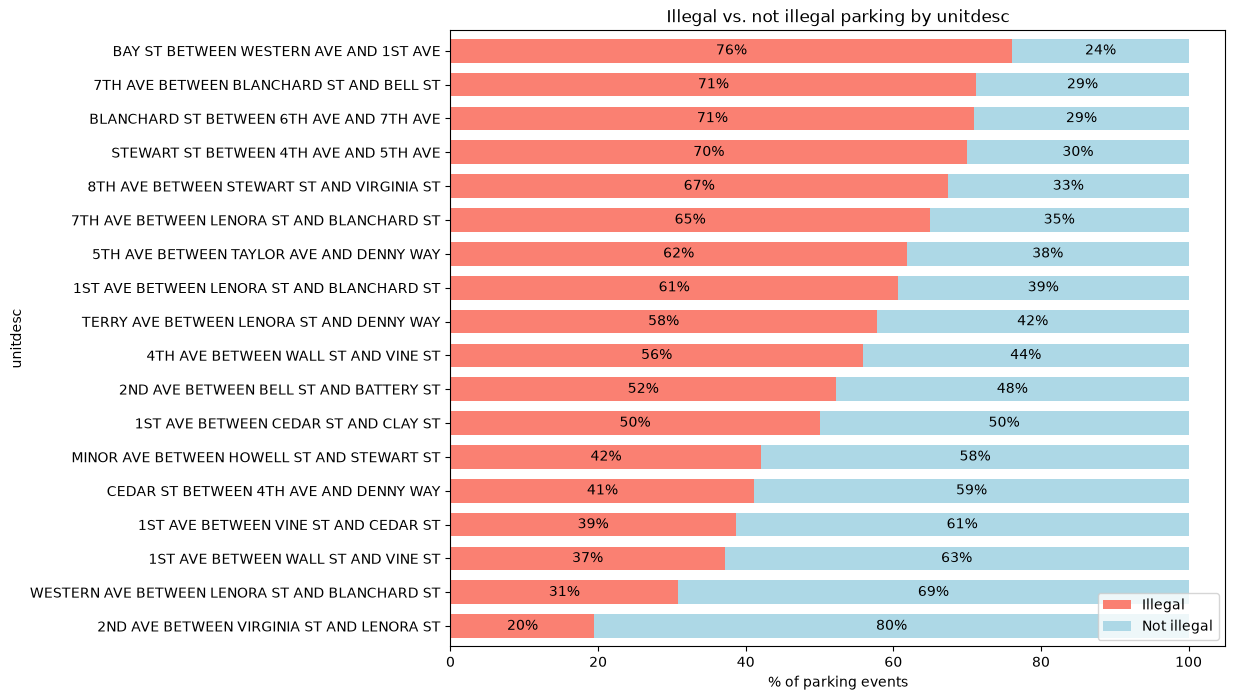

In [ ]:
bar_axis = pd.crosstab(
    idax1_with_weather['unitdesc'],
    idax1_with_weather['illegally_parked'].map({True: 'Illegal', False: 'Not illegal'}),
    normalize='index',
).mul(100).sort_values('Illegal').plot(
    kind='barh', stacked=True, figsize=(10, 8), width=0.7, color={'Illegal': 'salmon', 'Not illegal': 'lightblue'},
)

for segment in bar_axis.containers:
    bar_axis.bar_label(segment, label_type='center', fmt='%.0f%%')

plt.xlabel('% of parking events')
plt.ylabel('unitdesc')
plt.title('Illegal vs. not illegal parking by unitdesc')
plt.legend(title='', loc='lower right')
plt.show()

In [ ]:
pd.crosstab(idax1_with_weather['unitdesc'], idax1_with_weather['illegally_parked']).assign(
    percent_illegal=(idax1_with_weather.groupby('unitdesc')['illegally_parked'].mean() * 100).round(2).astype(str) + '%',
    PAIDAREA=idax1_with_weather.groupby('unitdesc')['PAIDAREA'].first(),
).sort_values('percent_illegal', key=lambda column: column.str.rstrip('%').astype(float), ascending=False)

illegally_parked,False,True,percent_illegal,PAIDAREA
unitdesc,,,,
BAY ST BETWEEN WESTERN AVE AND 1ST AVE,21,67,76.14%,Belltown
7TH AVE BETWEEN BLANCHARD ST AND BELL ST,44,109,71.24%,Denny Triangle
BLANCHARD ST BETWEEN 6TH AVE AND 7TH AVE,54,132,70.97%,Denny Triangle
STEWART ST BETWEEN 4TH AVE AND 5TH AVE,9,21,70.0%,Belltown
8TH AVE BETWEEN STEWART ST AND VIRGINIA ST,30,62,67.39%,Denny Triangle
7TH AVE BETWEEN LENORA ST AND BLANCHARD ST,81,150,64.94%,Denny Triangle
5TH AVE BETWEEN TAYLOR AVE AND DENNY WAY,21,34,61.82%,Belltown
1ST AVE BETWEEN LENORA ST AND BLANCHARD ST,52,80,60.61%,Belltown
TERRY AVE BETWEEN LENORA ST AND DENNY WAY,60,82,57.75%,Denny Triangle


##### Illgally parked per zone by park by month

In [ ]:
pd.to_datetime(idax1_with_weather['date']).agg(['min', 'max']) 

min   2024-04-30
max   2024-06-13
Name: date, dtype: datetime64[s]

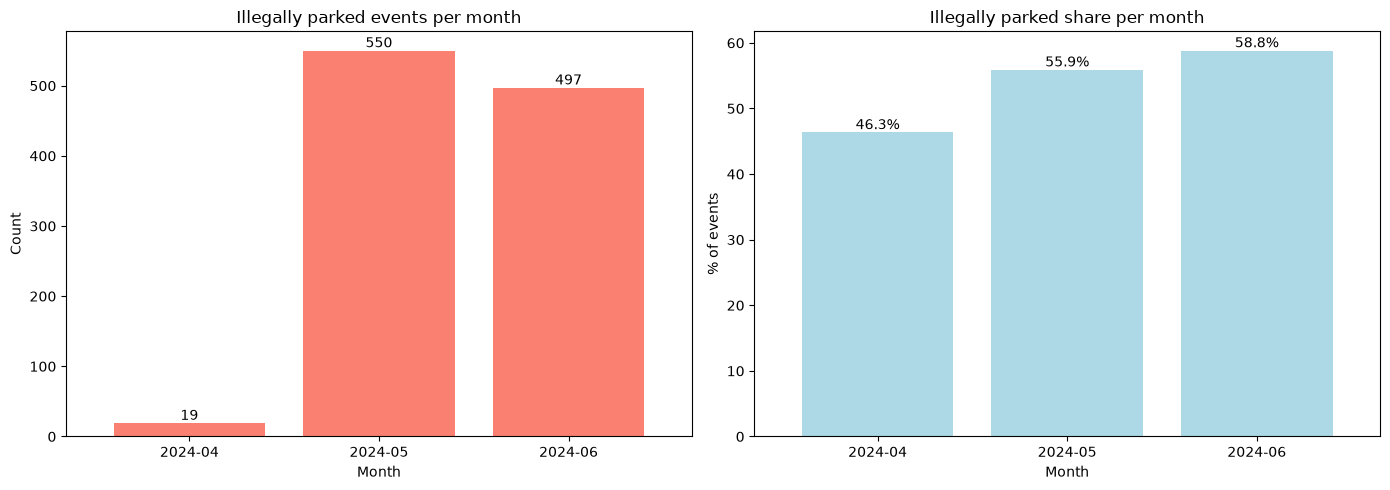

In [ ]:
month_of_event = pd.to_datetime(idax1_with_weather['date']).dt.to_period('M').astype(str)

figure, (count_axis, percent_axis) = plt.subplots(1, 2, figsize=(14, 5))

illegal_by_month = idax1_with_weather.groupby(month_of_event)['illegally_parked']

illegal_by_month.sum().plot(kind='bar', ax=count_axis, color='salmon', width=0.8)
count_axis.bar_label(count_axis.containers[0])
count_axis.set_title('Illegally parked events per month')
count_axis.set_xlabel('Month')
count_axis.set_ylabel('Count')

illegal_by_month.mean().mul(100).plot(kind='bar', ax=percent_axis, color='lightblue', width=0.8)
percent_axis.bar_label(percent_axis.containers[0], fmt='%.1f%%')
percent_axis.set_title('Illegally parked share per month')
percent_axis.set_xlabel('Month')
percent_axis.set_ylabel('% of events')

for axis in (count_axis, percent_axis):
    axis.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Illgally parked per zone by park start hour

C:\Users\dshan\AppData\Local\Temp\ipykernel_27332\2838211057.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  idax1_with_weather.groupby(['unitdesc', pd.to_datetime(idax1_with_weather['park_start']).dt.hour])['illegally_parked']


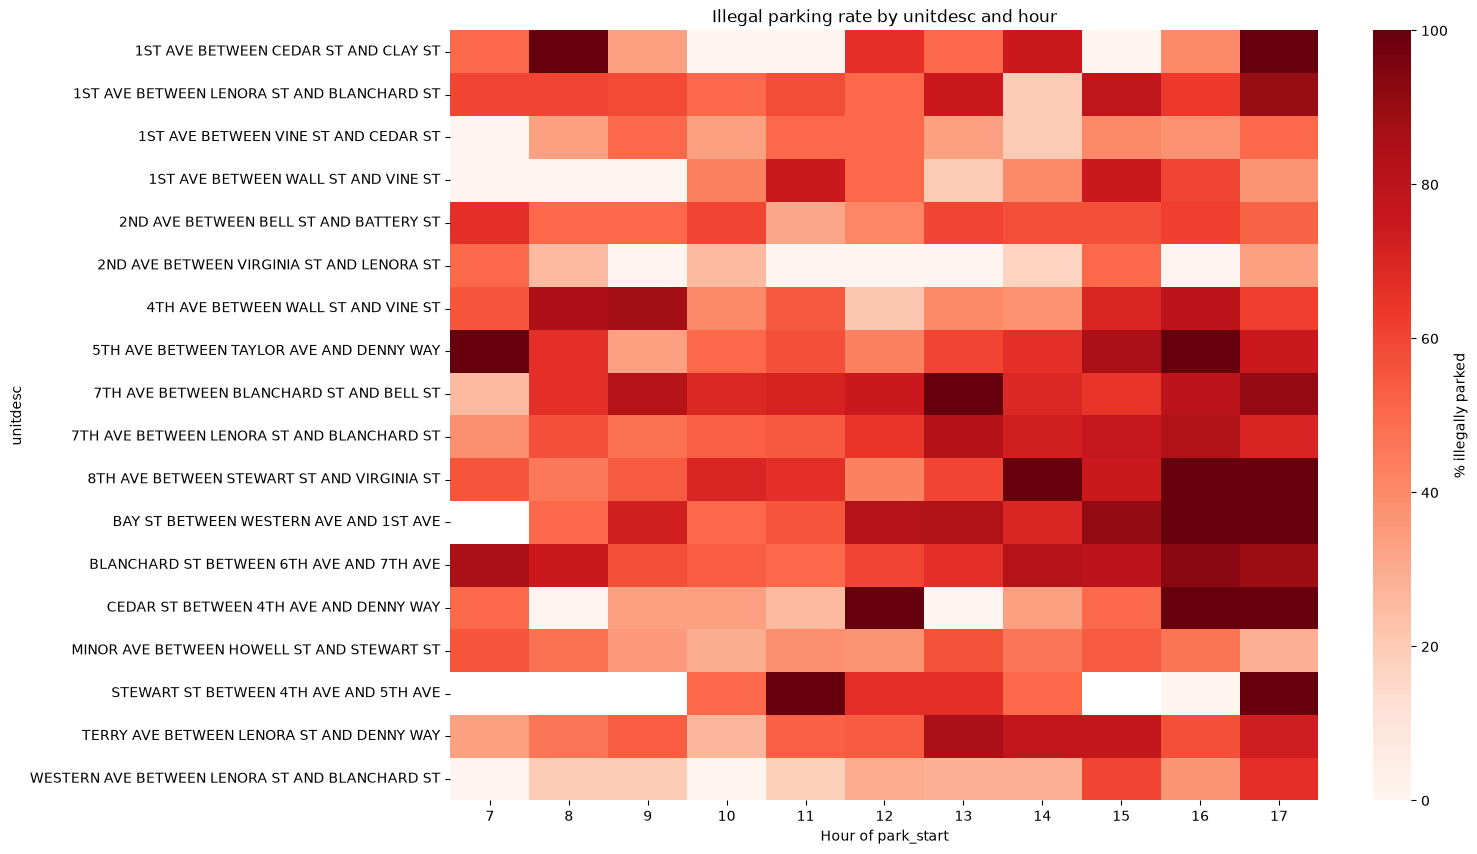

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))
sns.heatmap(
    idax1_with_weather.groupby(['unitdesc', pd.to_datetime(idax1_with_weather['park_start']).dt.hour])['illegally_parked']
        .mean().mul(100).unstack(),
    cmap='Reds',
    cbar_kws={'label': '% illegally parked'},
)
plt.xlabel('Hour of park_start')
plt.ylabel('unitdesc')
plt.title('Illegal parking rate by unitdesc and hour')
plt.show()

##### Illgally parked by zone by day of week

C:\Users\dshan\AppData\Local\Temp\ipykernel_27332\3383513176.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(area_rows['park_start']).dt.hour,
C:\Users\dshan\AppData\Local\Temp\ipykernel_27332\3383513176.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(area_rows['park_start']).dt.hour,


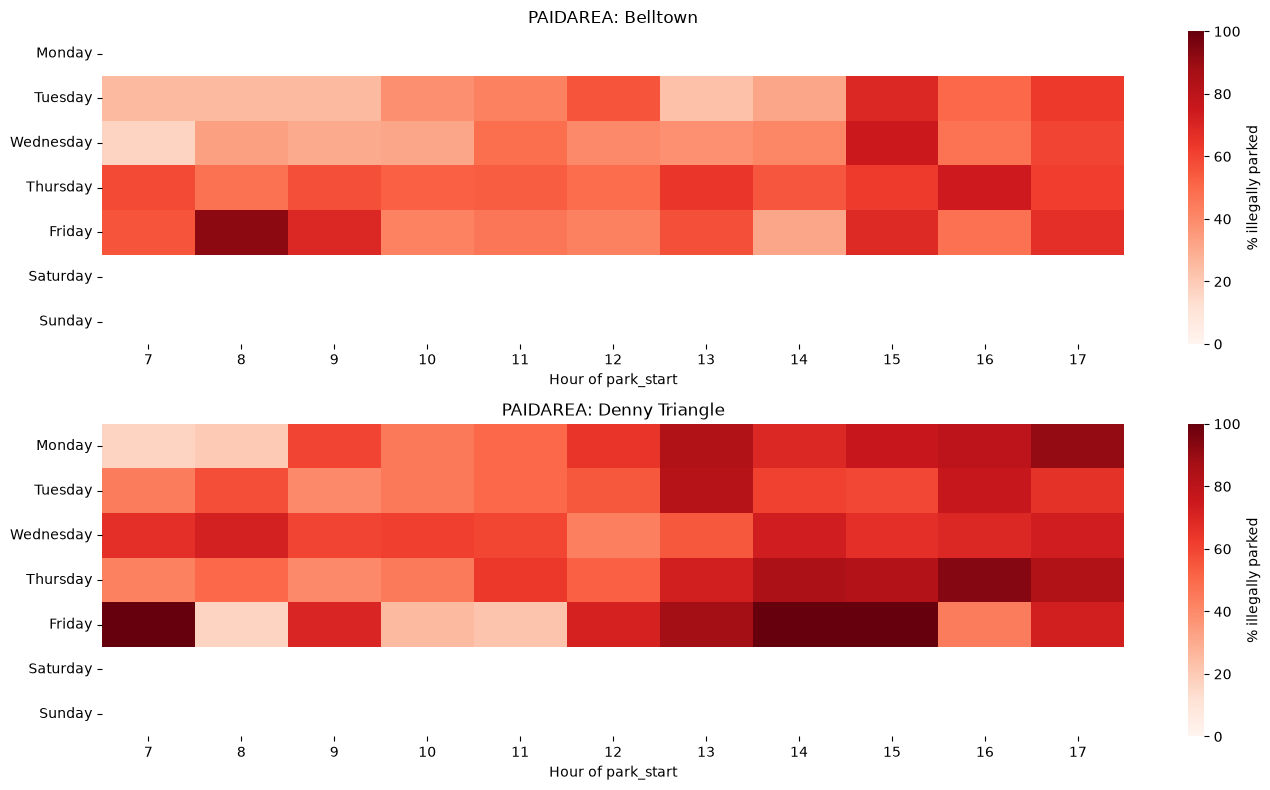

In [ ]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
paid_areas = idax1_with_weather['PAIDAREA'].dropna().unique()

figure, axes = plt.subplots(len(paid_areas), 1, figsize=(14, 4 * len(paid_areas)), squeeze=False)

for axis, paid_area in zip(axes.flat, paid_areas):
    area_rows = idax1_with_weather[idax1_with_weather['PAIDAREA'] == paid_area]
    sns.heatmap(
        area_rows.groupby([
            pd.to_datetime(area_rows['date']).dt.day_name(),
            pd.to_datetime(area_rows['park_start']).dt.hour,
        ])['illegally_parked'].mean().mul(100).unstack().reindex(weekday_order),
        cmap='Reds', vmin=0, vmax=100, ax=axis,
        cbar_kws={'label': '% illegally parked'},
    )
    axis.set_title(f'PAIDAREA: {paid_area}')
    axis.set_xlabel('Hour of park_start')
    axis.set_ylabel('')

plt.tight_layout()
plt.show()

In [ ]:
# check if belltown has no Monday data. Need to figure out why. 
belltown_rows = idax1_with_weather[idax1_with_weather['PAIDAREA'] == 'Belltown']
print(pd.to_datetime(belltown_rows['date']).dt.day_name().value_counts())
print(belltown_rows['illegally_parked'].isna().sum())

date
Thursday     325
Wednesday    216
Friday       215
Tuesday      132
Name: count, dtype: int64
0


##### activity_type by unitdesc

In [ ]:
pd.crosstab(idax1_with_weather['unitdesc'], idax1_with_weather['activity_type'])

activity_type,Construction,Emergency,Food Delivery,General Commercial (CM),Goods Transport,Other Transit,Parcel Carrier,Private,Public Transit,Rideshare,Service,Truck Rental
unitdesc,,,,,,,,,,,,
1ST AVE BETWEEN CEDAR ST AND CLAY ST,0,0,2,0,1,0,7,16,0,4,1,1
1ST AVE BETWEEN LENORA ST AND BLANCHARD ST,0,1,6,7,0,1,18,80,1,7,9,2
1ST AVE BETWEEN VINE ST AND CEDAR ST,0,1,3,5,3,0,5,17,0,9,1,0
1ST AVE BETWEEN WALL ST AND VINE ST,0,1,6,3,4,1,4,26,1,22,1,1
2ND AVE BETWEEN BELL ST AND BATTERY ST,0,0,22,8,18,0,8,82,0,12,4,3
2ND AVE BETWEEN VIRGINIA ST AND LENORA ST,0,0,10,0,8,0,5,8,0,5,3,2
4TH AVE BETWEEN WALL ST AND VINE ST,0,0,18,2,1,1,11,62,0,12,4,0
5TH AVE BETWEEN TAYLOR AVE AND DENNY WAY,1,0,3,0,5,0,3,34,0,6,3,0
7TH AVE BETWEEN BLANCHARD ST AND BELL ST,0,0,7,0,7,0,3,109,0,26,1,0


#### Rain/precipitation

In [ ]:
idax1_with_weather.shape

(1870, 31)

##### Rain vs Illegally Parked

In [ ]:
idax1_with_weather.groupby(idax1_with_weather['precipitation'] > 0)['illegally_parked'].agg(['sum', 'size', 'mean'])

,sum,size,mean
precipitation,,,
False,939,1583,0.593178
True,127,287,0.442509


In [ ]:
from scipy.stats import chi2_contingency
chi2_contingency(pd.crosstab(idax1_with_weather['precipitation'] > 0, idax1_with_weather['illegally_parked']))

Chi2ContingencyResult(statistic=np.float64(21.89232139942004), pvalue=np.float64(2.883855655038494e-06), dof=1, expected_freq=array([[680.60534759, 902.39465241],
       [123.39465241, 163.60534759]]))

In [ ]:
idax1_with_weather.assign(
    weather=idax1_with_weather['precipitation'].gt(0).map({True: 'Rain', False: 'Dry'}),
).groupby(['PAIDAREA', 'weather'])['illegally_parked'].agg(
    illegal='sum',
    total='size',
    percent_illegal=lambda flags: round(flags.mean() * 100, 1),
)

illegal  total  percent_illegal
PAIDAREA       weather                                 
Belltown       Dry          440    838             52.5
               Rain          16     50             32.0
Denny Triangle Dry          499    745             67.0
               Rain         111    237             46.8

##### Duration vs Rain

#### temperature

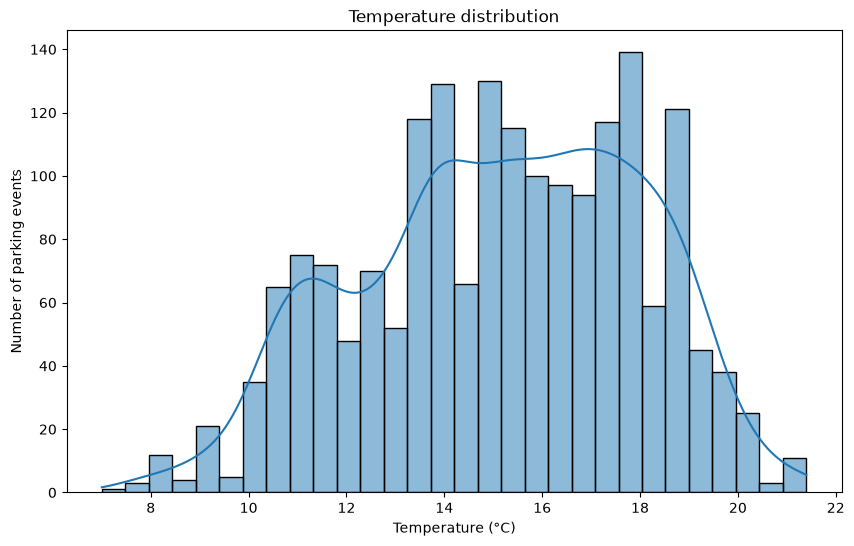

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=idax1_with_weather, x='temperature_2m', bins=30, kde=True)
plt.xlabel('Temperature (°C)')
plt.ylabel('Number of parking events')
plt.title('Temperature distribution')
plt.show()

##### Duration & Temperature

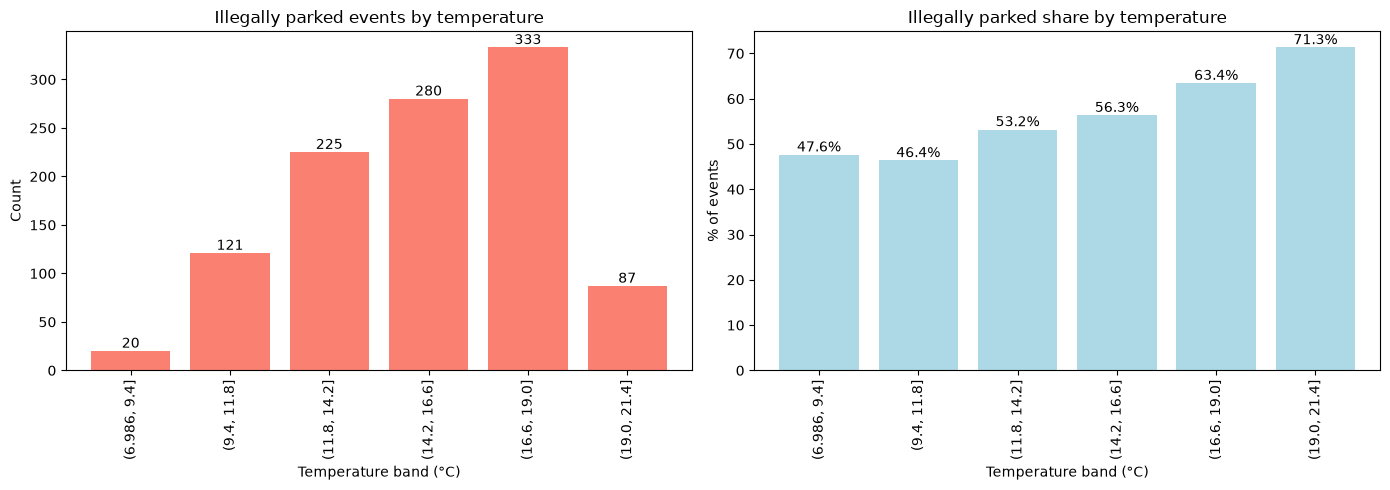

In [ ]:
temperature_band = pd.cut(idax1_with_weather['temperature_2m'], bins=6)
illegal_by_temperature = idax1_with_weather.groupby(temperature_band, sort=True)['illegally_parked']

figure, (count_axis, percent_axis) = plt.subplots(1, 2, figsize=(14, 5))

illegal_by_temperature.sum().plot(kind='bar', ax=count_axis, color='salmon', width=0.8)
count_axis.bar_label(count_axis.containers[0])
count_axis.set_title('Illegally parked events by temperature')
count_axis.set_xlabel('Temperature band (°C)')
count_axis.set_ylabel('Count')

illegal_by_temperature.mean().mul(100).plot(kind='bar', ax=percent_axis, color='lightblue', width=0.8)
percent_axis.bar_label(percent_axis.containers[0], fmt='%.1f%%')
percent_axis.set_title('Illegally parked share by temperature')
percent_axis.set_xlabel('Temperature band (°C)')
percent_axis.set_ylabel('% of events')

plt.tight_layout()
plt.show()

<Axes: xlabel='illegally_parked', ylabel='temperature_2m'>

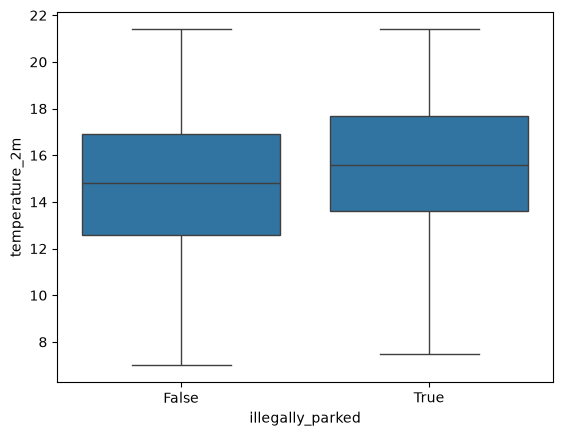

In [ ]:
sns.boxplot(data=idax1_with_weather, x='illegally_parked', y='temperature_2m')

In [ ]:
from scipy.stats import mannwhitneyu
mannwhitneyu(
    idax1_with_weather.loc[idax1_with_weather['illegally_parked'], 'temperature_2m'],
    idax1_with_weather.loc[~idax1_with_weather['illegally_parked'], 'temperature_2m'],
)

MannwhitneyuResult(statistic=np.float64(496161.5), pvalue=np.float64(4.883943208664509e-09))

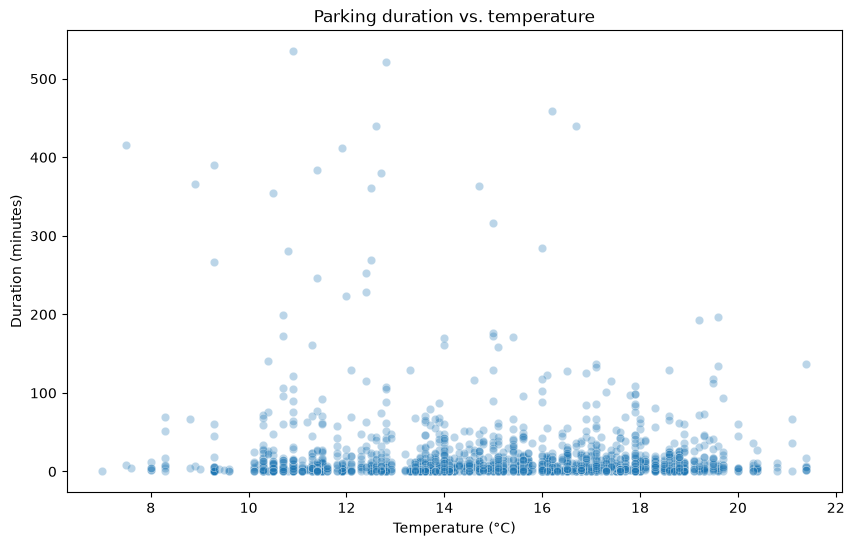

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=idax1_with_weather, x='temperature_2m', y='duration_min', alpha=0.3)
plt.xlabel('Temperature (°C)')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration vs. temperature')
plt.show()

In [ ]:
from scipy.stats import spearmanr
spearmanr(idax1_with_weather['duration_min'], idax1_with_weather['temperature_2m'], nan_policy='omit')

SignificanceResult(statistic=np.float64(0.03385168108388748), pvalue=np.float64(0.14338377369884509))

In [ ]:
idax1_with_weather[['duration_min', 'temperature_2m', 'precipitation']].corr(method='spearman')

,duration_min,temperature_2m,precipitation
duration_min,1.000000,0.033852,0.035649
temperature_2m,0.033852,1.000000,-0.444643
precipitation,0.035649,-0.444643,1.000000


#### duration 

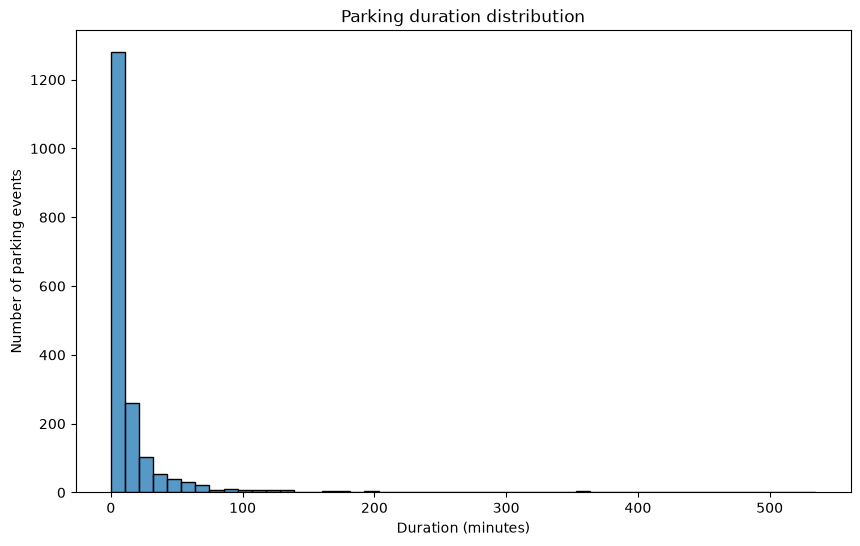

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=idax1_with_weather, x='duration_min', bins=50)
plt.xlabel('Duration (minutes)')
plt.ylabel('Number of parking events')
plt.title('Parking duration distribution')
plt.show()

##### duration of illgally parked car vs not 

In [ ]:
idax1_with_weather.groupby('illegally_parked')['duration_min'].agg(['min', 'max', 'median', 'mean', 'std'])

,min,max,median,mean,std
illegally_parked,,,,,
False,0.0,534.7,5.883333,19.37869,48.094064
True,0.0,521.1,4.666667,16.70566,44.080471


C:\Users\dshan\AppData\Local\Temp\ipykernel_27332\1464720728.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


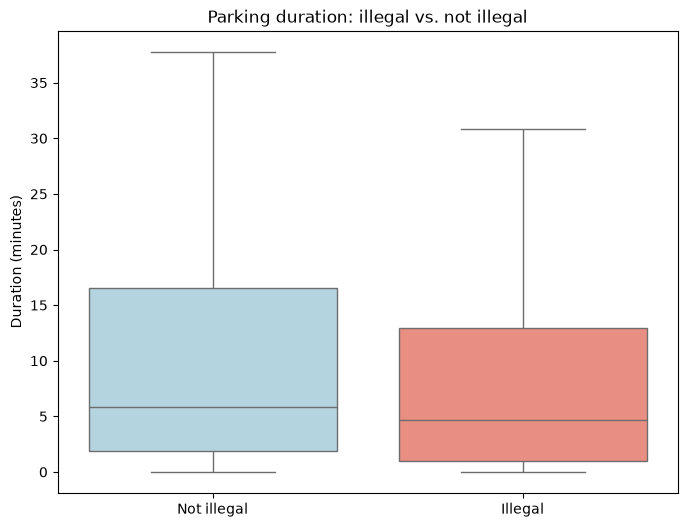

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data=idax1_with_weather.assign(
        parking_status=idax1_with_weather['illegally_parked'].map({True: 'Illegal', False: 'Not illegal'}),
    ),
    x='parking_status',
    y='duration_min',
    order=['Not illegal', 'Illegal'],
    palette={'Not illegal': 'lightblue', 'Illegal': 'salmon'},
    showfliers=False,
)
plt.xlabel('')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration: illegal vs. not illegal')
plt.show()

In [ ]:
import numpy as np
duration_edges = list(range(0, 65, 5)) + [float('inf')]
duration_labels = [f"{start}-{start + 5}" for start in range(0, 60, 5)] + ["60+"]

def stay_table(durations):
    stays_per_bin = pd.cut(durations.dropna(), bins=duration_edges, labels=duration_labels, right=False).value_counts().sort_index()
    return pd.DataFrame({
        "Stays": stays_per_bin,
        "Percent": stays_per_bin / stays_per_bin.sum() * 100,
        "Cumulative %": stays_per_bin.cumsum() / stays_per_bin.sum() * 100,
    })

combined_table = pd.concat(
    {
        "Illegal": stay_table(idax1_with_weather.loc[idax1_with_weather['illegally_parked'], 'duration_min']),
        "Not illegal": stay_table(idax1_with_weather.loc[~idax1_with_weather['illegally_parked'], 'duration_min']),
    },
    axis=1,
)
combined_table.index.name = "Duration (min)"

combined_table.style.format({
    (group, column): "{:.1f}%"
    for group in ["Illegal", "Not illegal"]
    for column in ["Percent", "Cumulative %"]
})


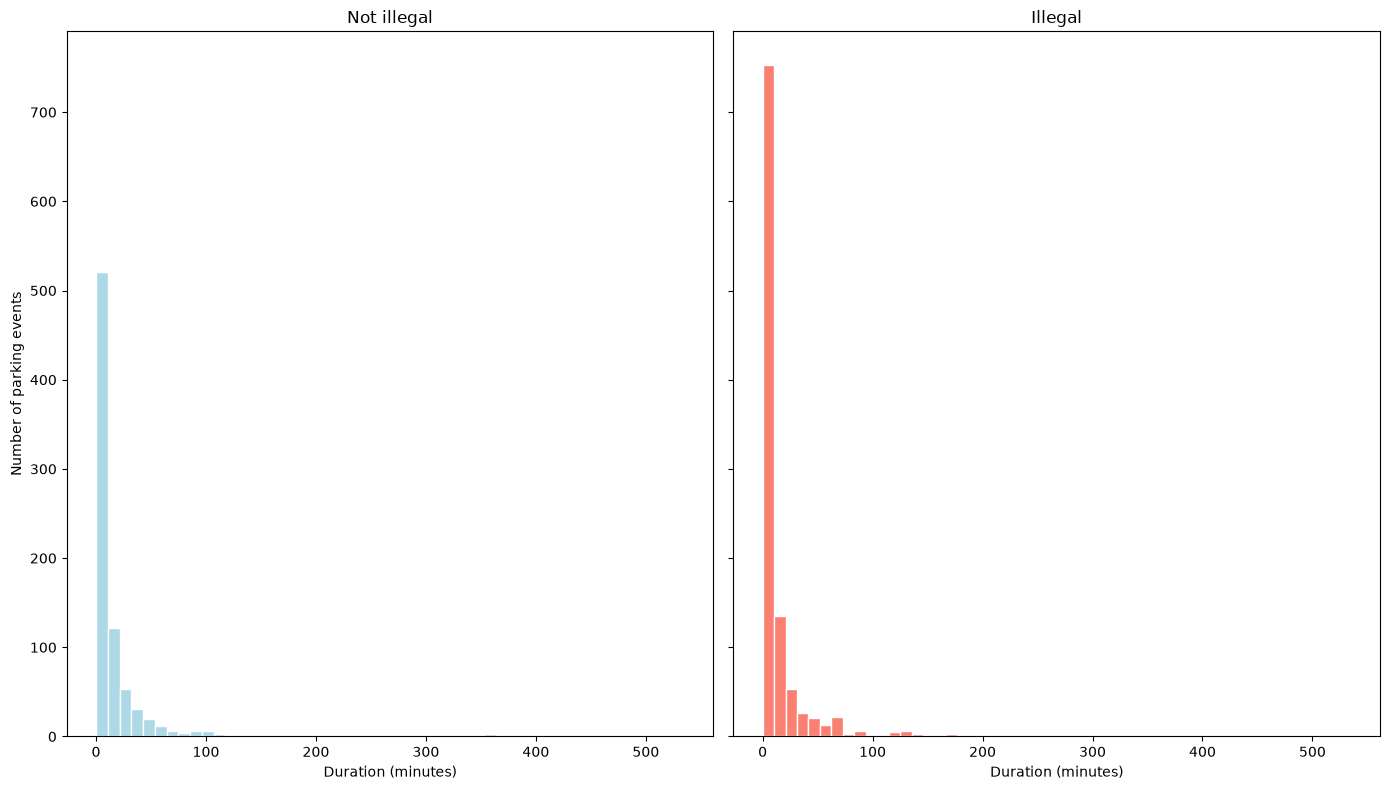

In [ ]:
figure, (not_illegal_axis, illegal_axis) = plt.subplots(1, 2, figsize=(14, 8), sharex=True, sharey=True)

not_illegal_axis.hist(idax1_with_weather.loc[~idax1_with_weather['illegally_parked'], 'duration_min'],
                      bins=50, color='lightblue', edgecolor='white')
not_illegal_axis.set_title('Not illegal')

illegal_axis.hist(idax1_with_weather.loc[idax1_with_weather['illegally_parked'], 'duration_min'],
                  bins=50, color='salmon', edgecolor='white')
illegal_axis.set_title('Illegal')

for axis in (not_illegal_axis, illegal_axis):
    axis.set_xlabel('Duration (minutes)')
not_illegal_axis.set_ylabel('Number of parking events')

plt.tight_layout()
plt.show()

##### Duration vs Precipitation

In [ ]:
idax1_with_weather[['duration_min', 'precipitation']].corr(method='spearman')

,duration_min,precipitation
duration_min,1.000000,0.035649
precipitation,0.035649,1.000000


In [ ]:
from scipy.stats import spearmanr
spearmanr(idax1_with_weather['duration_min'], idax1_with_weather['precipitation'], nan_policy='omit')

SignificanceResult(statistic=np.float64(0.03564914093761763), pvalue=np.float64(0.12330400147937688))

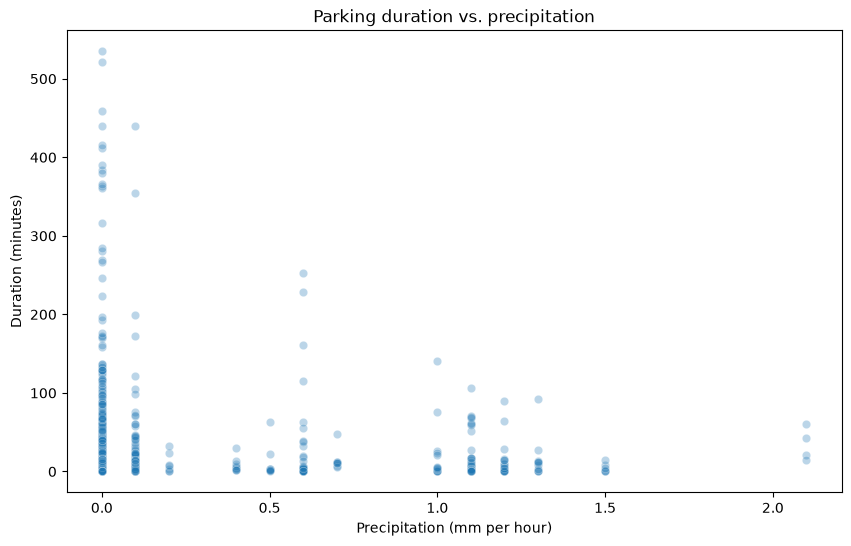

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=idax1_with_weather, x='precipitation', y='duration_min', alpha=0.3)
plt.xlabel('Precipitation (mm per hour)')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration vs. precipitation')
plt.show()

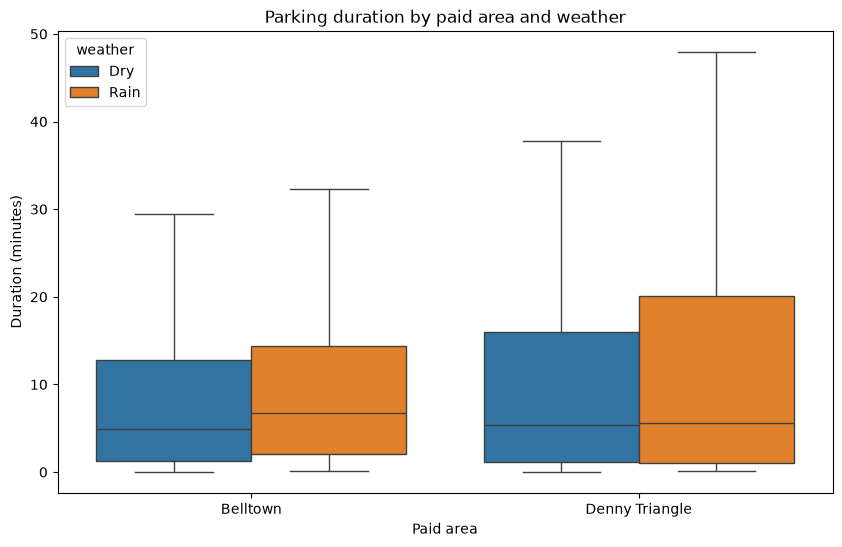

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=idax1_with_weather.assign(
        weather=idax1_with_weather['precipitation'].gt(0).map({True: 'Rain', False: 'Dry'}),
    ),
    x='PAIDAREA',
    y='duration_min',
    hue='weather',
    hue_order=['Dry', 'Rain'],
    showfliers=False,
)
plt.xlabel('Paid area')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration by paid area and weather')
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

rain_durations = idax1_with_weather.loc[idax1_with_weather['precipitation'] > 0, 'duration_min']
dry_durations = idax1_with_weather.loc[idax1_with_weather['precipitation'] == 0, 'duration_min']

print(mannwhitneyu(rain_durations, dry_durations, alternative='two-sided'))
print('median rain:', rain_durations.median(), '| median dry:', dry_durations.median())

MannwhitneyuResult(statistic=np.float64(239526.5), pvalue=np.float64(0.14177426070518853))
median rain: 5.666666666666667 | median dry: 5.15


##### Duration vs Activity Type

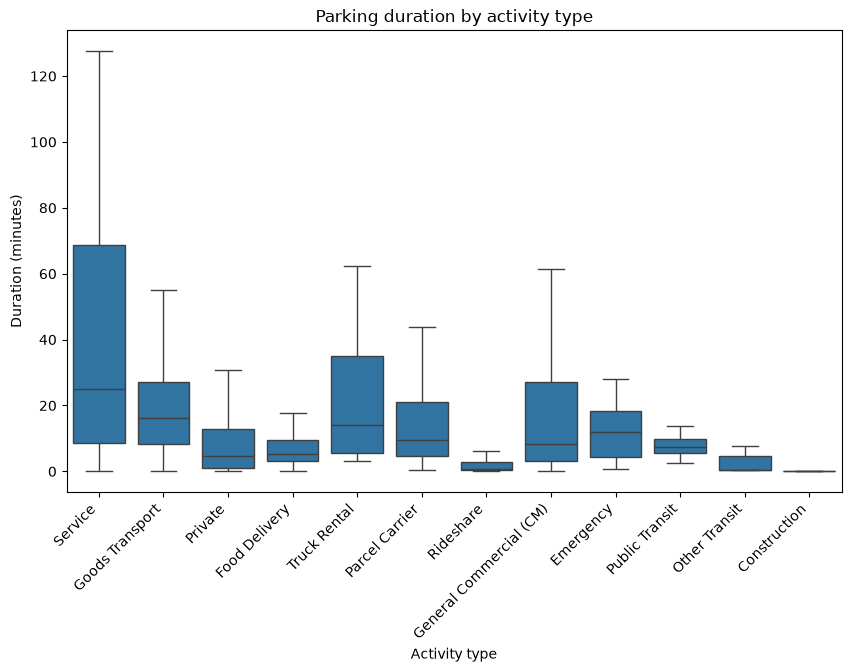

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=idax1_with_weather,
    x='activity_type',
    y='duration_min',
    showfliers=False,
)
plt.xlabel('Activity type')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration by activity type')
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
idax1_with_weather.groupby('activity_type')['duration_min'].agg(
    count='size',
    min='min',
    median='median',
    mean='mean',
    std='std',
    max='max',
).round(1).sort_values('median', ascending=False)

,count,min,median,mean,std,max
activity_type,,,,,,
Service,77,0.1,25.0,58.8,97.7,534.7
Goods Transport,91,0.1,16.1,25.3,44.8,380.1
Truck Rental,17,3.1,14.1,24.3,24.7,92.9
Emergency,8,0.8,11.9,12.7,10.8,27.9
Parcel Carrier,161,0.4,9.4,17.7,23.2,161.5
General Commercial (CM),71,0.1,8.3,41.6,86.5,415.4
Public Transit,4,2.4,7.5,7.8,4.7,13.8
Food Delivery,156,0.0,5.4,10.7,24.4,252.2
Private,1066,0.0,4.7,16.7,44.1,521.1


#### Day of week

In [ ]:
idax1_with_weather.groupby(
    pd.to_datetime(idax1_with_weather['date']).dt.day_name()
)['illegally_parked'].agg(
    illegal='sum',
    total='size',
    percent_illegal=lambda flags: round(flags.mean() * 100, 1),
).reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

,illegal,total,percent_illegal
date,,,
Monday,90.0,141.0,63.8
Tuesday,208.0,393.0,52.9
Wednesday,281.0,509.0,55.2
Thursday,327.0,537.0,60.9
Friday,160.0,290.0,55.2
Saturday,NaN,NaN,NaN
Sunday,NaN,NaN,NaN


In [ ]:
idax1_with_weather.groupby(
    [
        'PAIDAREA',
        pd.to_datetime(idax1_with_weather['date']).dt.day_name().astype(
            pd.CategoricalDtype(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], ordered=True)
        ).rename('day_of_week'),
    ],
    observed=True,
)['illegally_parked'].agg(
    illegal='sum',
    total='size',
    percent_illegal=lambda flags: round(flags.mean() * 100, 1),
)

illegal  total  percent_illegal
PAIDAREA       day_of_week                                 
Belltown       Tuesday           57    132             43.2
               Wednesday         93    216             43.1
               Thursday         189    325             58.2
               Friday           117    215             54.4
Denny Triangle Monday            90    141             63.8
               Tuesday          151    261             57.9
               Wednesday        188    293             64.2
               Thursday         138    212             65.1
               Friday            43     75             57.3

##### Day of Week vs Duration

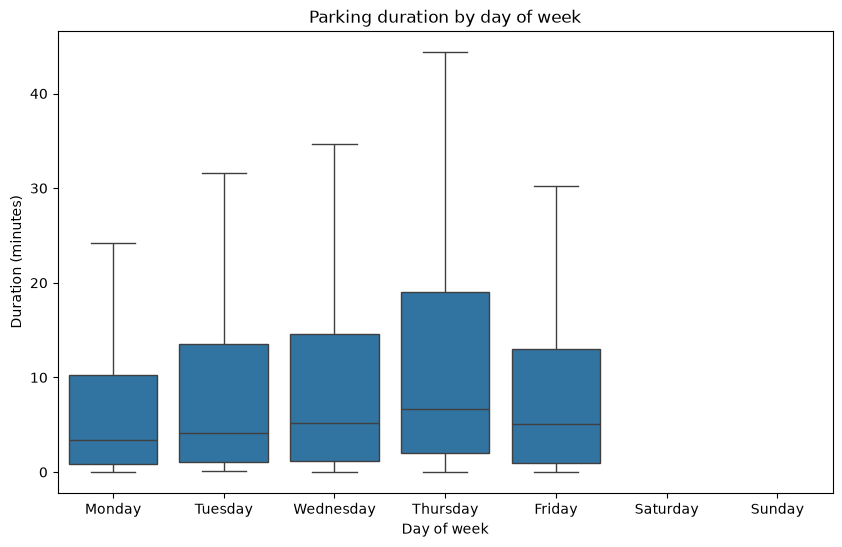

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=idax1_with_weather.assign(day_of_week=pd.to_datetime(idax1_with_weather['date']).dt.day_name()),
    x='day_of_week',
    y='duration_min',
    order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    showfliers=False,
)
plt.xlabel('Day of week')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration by day of week')
plt.show()

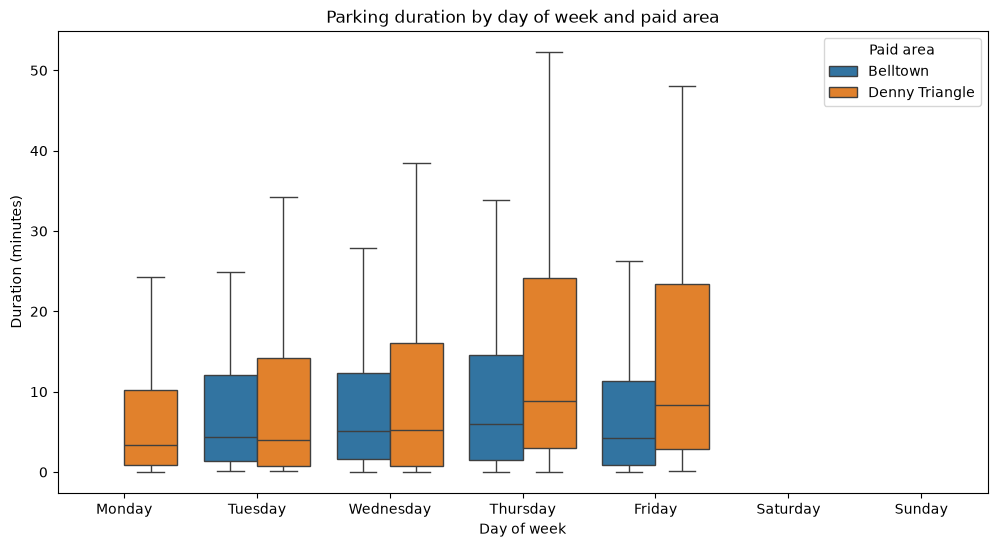

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=idax1_with_weather.assign(day_of_week=pd.to_datetime(idax1_with_weather['date']).dt.day_name()),
    x='day_of_week',
    y='duration_min',
    hue='PAIDAREA',
    order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'],
    showfliers=False,
)
plt.xlabel('Day of week')
plt.ylabel('Duration (minutes)')
plt.title('Parking duration by day of week and paid area')
plt.legend(title='Paid area')
plt.show()

In [ ]:
loading_6pm_with_duration = idax1_with_weather.copy()
loading_6pm_with_duration['dur_min'] = pd.to_timedelta(
    loading_6pm_with_duration['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60
loading_6pm_with_duration['start_hour'] = loading_6pm_with_duration['park_start'].str.split(':').str[0].astype(int)

for area, area_rows in loading_6pm_with_duration.groupby('PAIDAREA'):
    print(f"\n{area} ({len(area_rows)} stays)")
    display(area_rows.groupby('start_hour')['dur_min']
                     .describe(percentiles=[.25, .5, .75, .9])
                     .round(1))



Belltown (888 stays)


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,31.0,35.1,113.2,0.2,0.9,5.7,9.4,26.8,534.7
8,49.0,32.7,73.6,0.1,1.2,7.2,22.8,82.4,415.4
9,72.0,18.9,44.1,0.1,1.3,6.3,15.4,39.8,269.3
10,76.0,24.6,70.1,0.1,1.7,4.9,14.0,42.5,440.0
11,105.0,13.8,22.5,0.1,1.3,4.6,15.6,39.9,108.2
12,98.0,14.6,22.7,0.1,2.0,6.2,15.8,33.9,129.4
13,105.0,16.2,39.2,0.0,1.2,6.1,13.4,36.2,316.6
14,91.0,10.8,15.1,0.2,2.4,5.8,11.8,28.6,86.1
15,80.0,12.5,23.6,0.0,1.4,4.5,10.1,36.1,136.9



Denny Triangle (982 stays)


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,63.0,27.4,80.4,0.1,0.4,3.6,13.7,54.8,411.8
8,87.0,25.4,77.1,0.1,0.4,1.5,13.6,46.6,521.1
9,95.0,15.9,46.9,0.1,0.5,2.9,9.3,31.8,384.1
10,87.0,28.7,79.4,0.1,1.4,6.7,15.3,50.4,459.1
11,121.0,19.0,32.9,0.1,2.7,7.5,18.3,46.0,198.7
12,94.0,28.0,52.4,0.0,2.7,6.2,19.8,89.5,252.2
13,79.0,20.3,40.4,0.1,1.9,5.8,18.6,49.4,284.9
14,84.0,15.0,25.2,0.1,2.0,6.4,17.0,30.5,136.8
15,89.0,16.3,24.4,0.1,1.4,5.5,18.8,46.2,108.9


#### passenger_inout, driver_out

In [ ]:
pd.crosstab(idax1_with_weather['passenger_inout'], idax1_with_weather['illegally_parked'])

illegally_parked,False,True
passenger_inout,,
No,616,735
Yes,188,331


In [ ]:
pd.crosstab(idax1_with_weather['driver_out'], idax1_with_weather['illegally_parked'])

illegally_parked,False,True
driver_out,,
No,256,591
Yes,548,475


#### cvlz_permit_vid

In [ ]:
pd.crosstab(idax1_with_weather['CVLZ_permit_vid'], idax1_with_weather['illegally_parked'])

illegally_parked,False,True
CVLZ_permit_vid,,
No,645,1007
Unclear,51,26
Yes,108,33


#### Car Body Type

### Looking at Car Body Type 

In [ ]:
pd.crosstab(idax1_with_weather['body_type'], idax1_with_weather['illegally_parked']).assign(
    percent_illegal=(idax1_with_weather.groupby('body_type')['illegally_parked'].mean() * 100).round(1)
).sort_values('percent_illegal', ascending=False)

illegally_parked,False,True,percent_illegal
body_type,,,
Motorcycle,0,3,100.0
Passenger Vehicle,423,1061,71.5
Van,143,2,1.4
Bus,1,0,0.0
Bus/Other Transit,16,0,0.0
Minivan,44,0,0.0
CM Pickup,27,0,0.0
Single Unit Truck,92,0,0.0
Step-Van,56,0,0.0


In [ ]:
# cross tab
(pd.crosstab(idax1_loading_zones['body_type'],
             idax1_loading_zones['activity_type'],
             normalize='index',
             dropna=False) * 100).round(1)


activity_type,Construction,Emergency,Food Delivery,General Commercial (CM),Goods Transport,Other Transit,Parcel Carrier,Private,Public Transit,Rideshare,Service,Truck Rental
body_type,,,,,,,,,,,,
Bus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0
Bus/Other Transit,0.0,0.0,0.0,0.0,0.0,81.2,0.0,0.0,18.8,0.0,0.0,0.0
CM Pickup,0.0,0.0,3.7,7.4,0.0,0.0,0.0,0.0,0.0,0.0,88.9,0.0
Minivan,0.0,2.3,4.5,47.7,9.1,0.0,6.8,0.0,0.0,0.0,29.5,0.0
Motorcycle,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0
Passenger Vehicle,0.0,0.4,10.1,0.5,0.0,0.0,3.4,71.5,0.0,13.8,0.3,0.0
Single Unit Truck,1.1,0.0,2.2,7.6,73.9,0.0,3.3,0.0,0.0,0.0,5.4,6.5
Step-Van,0.0,0.0,0.0,3.6,0.0,0.0,89.3,0.0,0.0,0.0,7.1,0.0
Trailer Truck,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0


In [ ]:
# duration by start hour
d = idax1_loading_zones.copy()
d['dur_min'] = pd.to_timedelta(d['total_duration'].replace('<null>', pd.NA)).dt.total_seconds() / 60
d['start_hour'] = d['park_start'].str.split(':').str[0].astype(int)

(d.groupby('start_hour')['dur_min']
   .describe(percentiles=[.25, .5, .75, .9])
   .round(1))


,count,mean,std,min,25%,50%,75%,90%,max
start_hour,,,,,,,,,
7,94.0,30.0,92.0,0.1,0.7,4.2,10.2,45.4,534.7
8,136.0,28.0,75.7,0.1,0.5,3.7,18.6,64.9,521.1
9,167.0,17.2,45.6,0.1,0.6,4.0,12.0,37.2,384.1
10,163.0,26.8,75.0,0.1,1.4,5.6,15.1,46.6,459.1
11,226.0,16.6,28.6,0.1,1.6,6.1,16.8,44.2,198.7
12,192.0,21.2,40.5,0.0,2.0,6.2,18.4,54.9,252.2
13,184.0,17.9,39.7,0.0,1.5,6.0,15.4,39.2,316.6
14,175.0,12.8,20.6,0.1,2.1,6.2,13.6,30.1,136.8
15,169.0,14.5,24.0,0.0,1.4,5.2,15.3,43.7,136.9


### Number of Cars / Element Key/ Time 
Maximum cars parked at the same time on each segment

**What this does:** for each street segment (`ELMNTKEY`), finds the most vehicles parked at the same time in the surveyed loading zones, for all vehicles and for illegally parked vehicles only.

**How it works**

| Step | What happens |
|---|---|
| 1. Arrivals | Each parking stay gets a row at `park_start` with `change` = +1. |
| 2. Departures | Each parking stay gets a row at `park_end` with `change` = −1. |
| 3. Timeline | Both sets of rows are stacked and sorted by segment, date and time. At equal times, departures come first. |
| 4. Running count | A cumulative sum of `change` gives `cars_present` after each event. It restarts for each segment and date. |
| 5. Maximum | The highest `cars_present` for each segment across all its survey days. |

**Output:** `max_cars_per_segment`, one row per segment.

| Column | Meaning |
|---|---|
| `max_all_cars` | Peak number of all vehicles parked at once |
| `max_illegal_cars` | Peak number of illegally parked vehicles at once (`activity_type == 'Private'`) |

**Results:** the highest peaks are 6 vehicles of any kind (segment 81114) and 5 illegally parked vehicles (segments 31058 and 81114).

**Limitations**

- These are peaks, not typical levels.
- The two columns are calculated separately, so their peaks may occur at different times or on different days.
- Each segment was surveyed on only 2 or 3 days.
- These are observed vehicles, not curb capacity.
- "Illegally parked" is a proxy chosen by the group, not a confirmed violation.
- A stay with identical start and end times is not counted.

In [169]:
def max_cars_at_once(parking_stays):
    segment_and_date = parking_stays[['ELMNTKEY', 'date']]
    arrivals = segment_and_date.assign(time=pd.to_timedelta(parking_stays['park_start']), change=1)
    departures = segment_and_date.assign(time=pd.to_timedelta(parking_stays['park_end']), change=-1)

    # departures (-1) sort before arrivals (+1) when the times are equal
    changes = pd.concat([arrivals, departures]).sort_values(['ELMNTKEY', 'date', 'time', 'change'])
    changes['cars_present'] = changes.groupby(['ELMNTKEY', 'date'])['change'].cumsum()
    return changes.groupby('ELMNTKEY')['cars_present'].max()

max_cars_per_segment = pd.DataFrame({
    'max_all_cars': max_cars_at_once(idax1_with_weather),
    'max_illegal_cars': max_cars_at_once(idax1_with_weather[idax1_with_weather['illegally_parked']]),
}).fillna(0).astype(int).sort_values('max_illegal_cars', ascending=False)

max_cars_per_segment

,max_all_cars,max_illegal_cars
ELMNTKEY,,
31058,5,5
81114,6,5
25713,4,4
1021,5,4
77229,5,4
57193,4,3
57194,4,3
76054,3,3
81113,3,3


## GIS Data Analysis
Limitation: parking events can't be tied to a specific curb space

The IDAX parking data and the SDOT GIS data can only be matched reliably on ELMNTKEY. Not all IDAX space types appear in the GIS data under the same key; some may be missing or recorded under a different space type. In addition, a single ELMNTKEY can carry more than one space type, and it covers several curb spaces in the GIS data, each with its own geometry, even among spaces of the same type. The match is therefore one-to-many, and we can't determine which curb space a parking event occurred at.

We therefore analyze the data at the ELMNTKEY level, representing each key with a single central location calculated from its GIS geometry. This is a reasonable approximation because each of the 28 surveyed keys covers one side of a single block, about 75 to 125 m long.

In [138]:
idax1_with_weather.groupby('unitdesc')['ELMNTKEY'].unique().loc[lambda keys_per_description: keys_per_description.str.len() > 1]

unitdesc
1ST AVE BETWEEN LENORA ST AND BLANCHARD ST          [1022, 1021]
1ST AVE BETWEEN VINE ST AND CEDAR ST              [68917, 68918]
1ST AVE BETWEEN WALL ST AND VINE ST               [24045, 24046]
4TH AVE BETWEEN WALL ST AND VINE ST               [28958, 28957]
7TH AVE BETWEEN BLANCHARD ST AND BELL ST          [53433, 53434]
7TH AVE BETWEEN LENORA ST AND BLANCHARD ST        [76054, 76053]
BLANCHARD ST BETWEEN 6TH AVE AND 7TH AVE          [77229, 77230]
MINOR AVE BETWEEN HOWELL ST AND STEWART ST        [57194, 57193]
TERRY AVE BETWEEN LENORA ST AND DENNY WAY         [81114, 81113]
WESTERN AVE BETWEEN LENORA ST AND BLANCHARD ST    [58810, 58809]
Name: ELMNTKEY, dtype: object

In [139]:
# group loading zone types (from the markdown cell above) by SPACETYPEDESC
LOADING_GROUPS = {
    "General load/unload": ["LOAD/UNLOAD ZONE", "PAY STATION - LOAD/UNLOAD ZONE",
                            "TIME LIMIT - LOAD/UNLOAD ZONE", "FULL-TIME PAID LOADING"],
    "Commercial/truck": ["COMMERCIAL VEHICLE LOAD ZONE", "TRUCK LOAD/UNLOAD ZONE",
                         "PAY STATION - CVLZ", "TIME LIMIT - TRUCK L/U ZONE"],
    "Passenger (PLZ)": ["PASSENGER LOAD ZONE", "PAY STATION - PLZ",
                        "PASSENGER LOAD ZONE - VENDING ZONE", "TIME LIMIT - PLZ"],
    "Shared/hybrid": ["CVLZ - PLZ", "CVLZ - BUS ZONE"],
}

# reverse lookup: description -> group name
desc_to_group = {d: g for g, descs in LOADING_GROUPS.items() for d in descs}

gis_loading = gis_curb_spaces[gis_curb_spaces["SPACETYPEDESC"].isin(desc_to_group)].copy()
gis_loading["zone_group"] = gis_loading["SPACETYPEDESC"].map(desc_to_group)

print(gis_loading.shape)
print(gis_loading["zone_group"].value_counts())

(2276, 29)
zone_group
General load/unload    933
Passenger (PLZ)        833
Commercial/truck       464
Shared/hybrid           46
Name: count, dtype: int64


**Checking that each `ELMNTKEY` is a single location**

The model treats each surveyed `ELMNTKEY` as one location. A key covers many curb spaces, each stored in GIS as its own line, so this check confirms that all the lines for a key sit in the same place.

| Code | What it does |
|---|---|
| `isin(idax1_with_weather['ELMNTKEY'].unique())` | Keeps the GIS curb rows whose key appears in the survey data used here. |
| `to_crs(epsg=32610)` | Converts the coordinates to meters. |
| `groupby('ELMNTKEY').agg(...)` | For each key, counts the curb rows, the different street sides and the different block IDs. |
| `geometry.bounds` | Finds the westmost, eastmost, southmost and northmost point of each curb line. |
| `span_m` | Draws the smallest upright box around all of a key's lines and measures its diagonal in meters. |
| `sort_values('span_m', ...)` | Lists the most spread-out keys first, so outliers are easy to see. |

**Results:** all 28 keys have exactly one side and one block, and their spans range from about 75 to 125 m, with no outliers. Each key therefore corresponds to one side of a single block and can be treated as one location.

**Limitation:** this checks the GIS data only. It does not confirm that survey observers assigned the correct key to each parking event.

In [140]:
rows_on_idax_segments = gis_loading[
    gis_loading['ELMNTKEY'].isin(idax1_with_weather['ELMNTKEY'].unique())
].to_crs(epsg=32610)

location_check = rows_on_idax_segments.groupby('ELMNTKEY').agg(
    curb_rows=('geometry', 'size'),
    sides=('SIDE', 'nunique'),
    blocks=('BLOCKID', 'nunique'),
)

bounds = rows_on_idax_segments.geometry.bounds.groupby(rows_on_idax_segments['ELMNTKEY'])
location_check['span_m'] = (
    (bounds['maxx'].max() - bounds['minx'].min())**2 + (bounds['maxy'].max() - bounds['miny'].min())**2
).pow(0.5).round(1)

print(len(location_check), "keys")
location_check.sort_values('span_m', ascending=False)

28 keys


,curb_rows,sides,blocks,span_m
ELMNTKEY,,,,
1021,4,1,1,99.6
76054,4,1,1,94.0
31058,8,1,1,92.9
57194,4,1,1,92.3
58810,3,1,1,85.7
25713,3,1,1,69.3
81113,3,1,1,68.2
68921,2,1,1,63.8
28957,2,1,1,56.2


c:\Users\dshan\OneDrive\Documents\school\uw_ms_cee\202609\cet513_transportation_network_and_optimization\project\.venv\Lib\site-packages\contextily\tile.py:680: UserWarning: The inferred zoom level of 19 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)


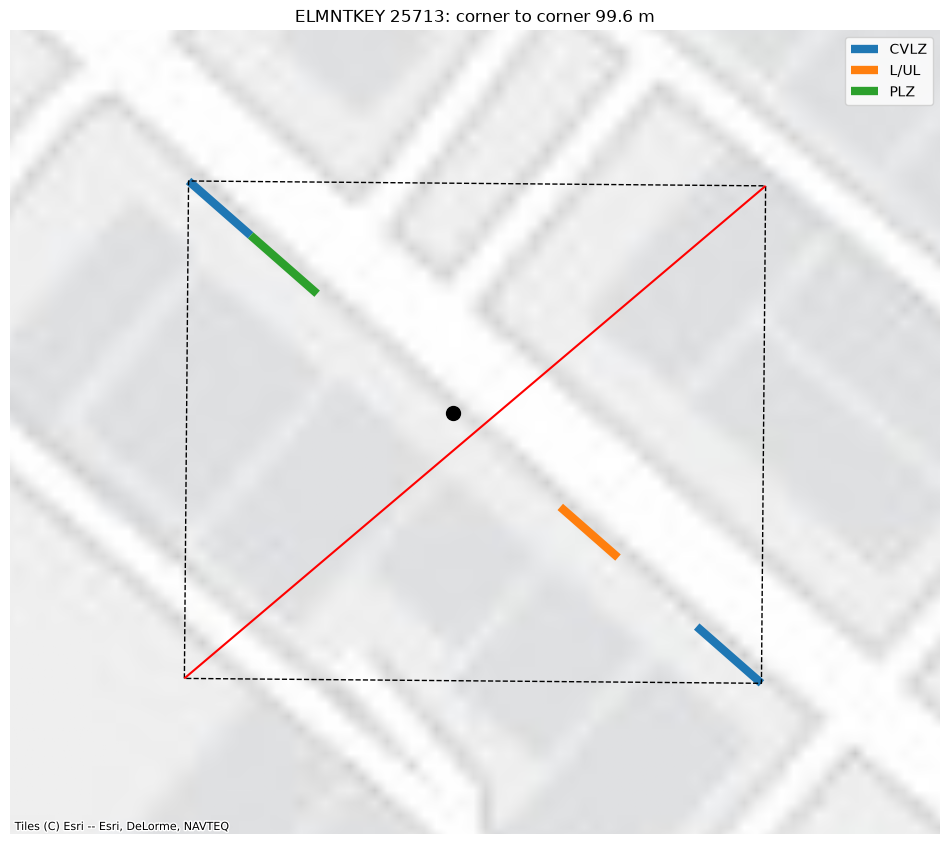

In [141]:
import matplotlib.pyplot as plt
import contextily as ctx
import geopandas as gpd
from shapely.geometry import box, LineString

one_key_rows = gis_loading[gis_loading['ELMNTKEY'] == 1021].to_crs(epsg=32610)
west, south, east, north = one_key_rows.total_bounds

bounding_box = gpd.GeoSeries([box(west, south, east, north)], crs=32610).to_crs(epsg=3857)
diagonal = gpd.GeoSeries([LineString([(west, south), (east, north)])], crs=32610)
if one_key_rows.geometry.union_all().centroid.y > (south + north) / 2:
    pass  # box and span are the same for either diagonal
central_point = gpd.GeoSeries([one_key_rows.geometry.union_all().centroid], crs=32610).to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))
one_key_rows.to_crs(epsg=3857).plot(ax=ax, column='SPACETYPE', legend=True, linewidth=6)
bounding_box.boundary.plot(ax=ax, color='black', linestyle='--', linewidth=1)
diagonal.to_crs(epsg=3857).plot(ax=ax, color='red', linewidth=1.5)
central_point.plot(ax=ax, color='black', markersize=100, zorder=3)

ax.margins(0.3)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_axis_off()
ax.set_title(f"ELMNTKEY 25713: corner to corner {diagonal.length.iloc[0]:.1f} m")
plt.show()

In [142]:
# compare
print(gis_loading['SPACETYPE'].unique(), idax1_with_weather['SPACETYPE'].unique())

<StringArray>
[  'TL-LUL',     'L/UL',     'CVLZ',      'PLZ',   'CVLZ-P',   'PS-LUL',
   'TL-PLZ',    'TRUCK',   'PS-PLZ', 'PLZ-VEND',  'PS-CVLZ',   'L/UL-P',
   'CVLZ-B',   'TL-TRK']
Length: 14, dtype: str <StringArray>
['CVLZ', 'PS-VEN', 'PS-CVLZ', 'L/UL', 'CVLZ/PS', 'LOAD']
Length: 6, dtype: str


In [143]:
idax1_with_weather['SPACETYPE'].value_counts()

SPACETYPE
CVLZ       1389
PS-CVLZ     153
CVLZ/PS     148
L/UL        112
LOAD         58
PS-VEN       10
Name: count, dtype: int64

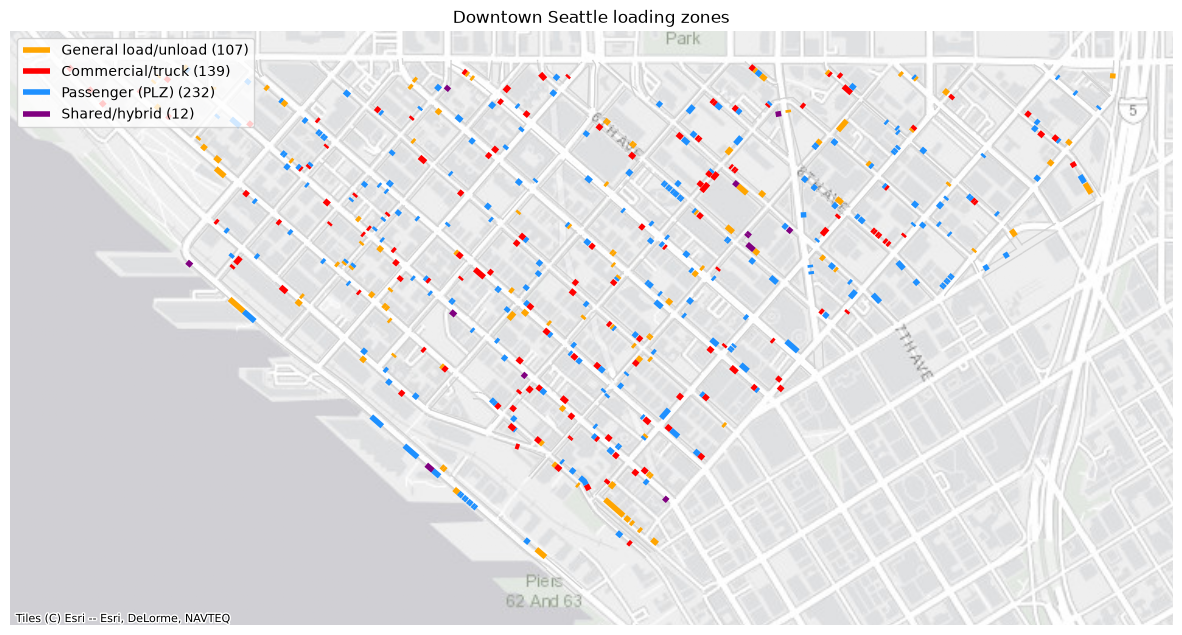

In [144]:
# map loading zones; edit DOWNTOWN_AREAS (PAIDAREA values) to define the study area
areas = ["Belltown", "Denny Triangle"]

COLORS = {"General load/unload": "orange", "Commercial/truck": "red",
          "Passenger (PLZ)": "dodgerblue", "Shared/hybrid": "purple"}

# basemap tiles are in Web Mercator (EPSG:3857), so reproject before plotting
dt_all = gis_curb_spaces[gis_curb_spaces["PAIDAREA"].isin(areas)].to_crs(epsg=3857)
dt_load = gis_loading[gis_loading["PAIDAREA"].isin(areas)].to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(15, 15))
dt_all.plot(ax=ax, color="lightgray", linewidth=1)  # all curb space as context
for group, color in COLORS.items():
    sub = dt_load[dt_load["zone_group"] == group]
    sub.plot(ax=ax, color=color, linewidth=4, label=f"{group} ({len(sub)})")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc="upper left")
ax.set_axis_off()
ax.set_title("Downtown Seattle loading zones")
plt.show()

In [145]:
idax_keys = idax1_with_weather['ELMNTKEY'].unique()

gis_curb_idax_segments = gis_loading[gis_loading['ELMNTKEY'].isin(idax_keys)]

print(len(idax_keys), "IDAX segments |", len(gis_curb_idax_segments), "curb rows")
print("IDAX segments missing from GIS:", (~pd.Series(idax_keys).isin(gis_loading['ELMNTKEY'])).sum())

28 IDAX segments | 68 curb rows
IDAX segments missing from GIS: 0


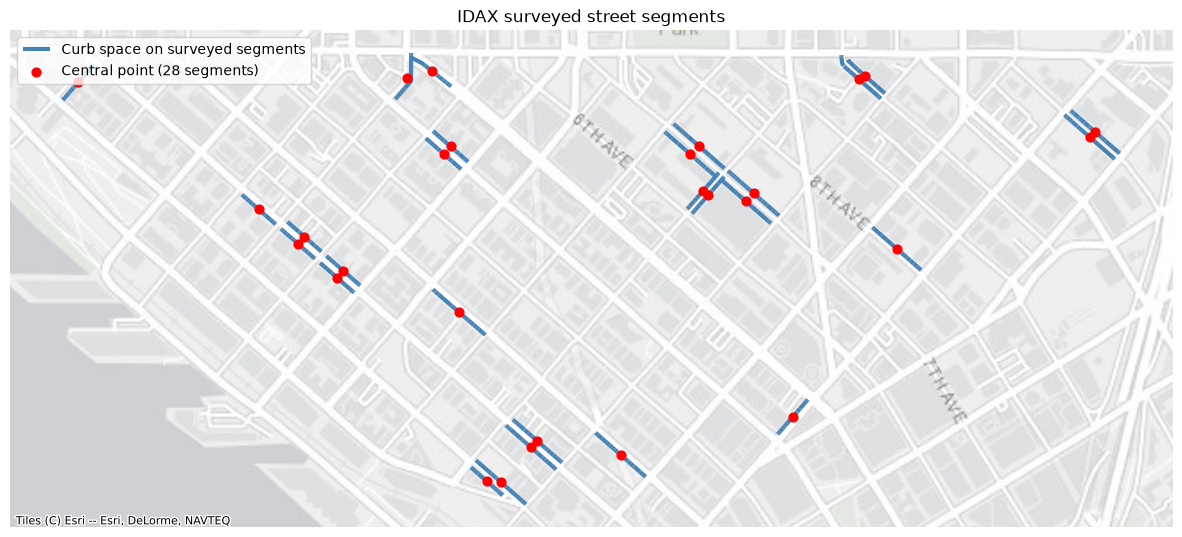

In [146]:
idax_keys = idax1_with_weather['ELMNTKEY'].unique()

# basemap tiles are in Web Mercator (EPSG:3857), so reproject before plotting
idax_curb_all = gis_curb_spaces[gis_curb_spaces['ELMNTKEY'].isin(idax_keys)]
segment_central_points = idax_curb_all.to_crs(epsg=32610).dissolve(by='ELMNTKEY').geometry.centroid.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(15, 15))
idax_curb_all.to_crs(epsg=3857).plot(ax=ax, color='steelblue', linewidth=3, label='Curb space on surveyed segments')
segment_central_points.plot(ax=ax, color='red', markersize=40, zorder=3, label=f'Central point ({len(segment_central_points)} segments)')

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend(loc='upper left')
ax.set_axis_off()
ax.set_title('IDAX surveyed street segments')
plt.show()


### Limitations

In [152]:
study_areas = ['Belltown', 'Denny Triangle']

loading_segments = gis_loading[gis_loading['PAIDAREA'].isin(study_areas)].drop_duplicates('ELMNTKEY')

segment_coverage = loading_segments.assign(
    surveyed=loading_segments['ELMNTKEY'].isin(idax1_with_weather['ELMNTKEY'])
).groupby('PAIDAREA')['surveyed'].agg(loading_zone_segments='size', surveyed_segments='sum')

segment_coverage.loc['Total'] = segment_coverage.sum()
segment_coverage['percent_surveyed'] = (
    segment_coverage['surveyed_segments'] / segment_coverage['loading_zone_segments'] * 100
).round(1)

segment_coverage

,loading_zone_segments,surveyed_segments,percent_surveyed
PAIDAREA,,,
Belltown,176,17,9.7
Denny Triangle,79,11,13.9
Total,255,28,11.0


Limitation: incomplete coverage of loading zones. The IDAX observation data covers only 28 street segments (ELMNTKEY) in Belltown and Denny Triangle. SDOT's curb space inventory shows 255 segments with at least one loading zone in those two neighborhoods, so the survey covers 28 of them (11%): 17 of 176 in Belltown (9.7%) and 11 of 79 in Denny Triangle (13.9%). Loading zones here follow SDOT's space type descriptions and include commercial and truck, general load/unload, passenger and shared zones. Our optimization model, which routes a parking enforcement officer between loading zones (a traveling salesman problem, TSP), can therefore use observed activity for only about one in nine of these segments. A route built from this data would skip many segments that an officer would pass or need to check, so its length, time and coverage will not match a real patrol. The results should be read as a proof of concept on the surveyed segments, not as a schedule for all of Belltown and Denny Triangle, and certainly not for the whole city.

#### Finding distance between each segment
To measure distances between locations, we started with the SDOT curb space data for the 28 street segments (`ELMNTKEY`) that appear in the IDAX survey. Each curb space is stored as a line in longitude and latitude (degrees). Because degrees aren't a consistent unit of distance, we first reprojected the lines into UTM zone 10N (EPSG:32610), a flat coordinate system measured in meters that is accurate for the Seattle area. We then combined the curb space lines of each segment and took their centroid, giving one central point per segment with east-west and north-south coordinates in meters (`x_m` and `y_m`). Finally, we computed the straight-line (Euclidean) distance between every pair of central points, which gave a 28 × 28 table of segment-to-segment distances in meters (`segment_straight_m`).

Straight-line distance does not reflect how far an officer would actually walk, because walking is limited by the street layout and buildings. We use it as a baseline for comparison with walking distance on the street network, calculated in the next section.

##### by converting longitude and latitude 

In [156]:
segments = (
    gis_curb_spaces[gis_curb_spaces['ELMNTKEY'].isin(idax1_with_weather['ELMNTKEY'].unique())]
    .to_crs(epsg=32610)  # UTM zone 10N, in meters
    .dissolve(by='ELMNTKEY', aggfunc={'PAIDAREA': 'first', 'SIDE': 'first', 'BLOCKID': 'first'})
)

segments['x_m'] = segments.geometry.centroid.x
segments['y_m'] = segments.geometry.centroid.y

print(len(segments), "segments")
segments[['PAIDAREA', 'SIDE', 'BLOCKID', 'x_m', 'y_m']]

28 segments


,PAIDAREA,SIDE,BLOCKID,x_m,y_m
ELMNTKEY,,,,,
1021,Belltown,SW,01-21,549251.731715,5.273405e+06
1022,Belltown,NE,01-21,549263.006854,5.273417e+06
7265,Belltown,SW,05-26,549067.244746,5.274078e+06
9158,Belltown,SE,31-00,548431.649874,5.274053e+06
24045,Belltown,SW,01-25,548900.156815,5.273707e+06
24046,Belltown,NE,01-25,548911.291931,5.273719e+06
25713,Belltown,SW,02-23,549120.405803,5.273646e+06
28957,Belltown,SW,04-25,549089.770918,5.273930e+06
28958,Belltown,NE,04-25,549102.497649,5.273944e+06


In [157]:
from scipy.spatial.distance import cdist

segments['x_m'] = segments.geometry.centroid.x
segments['y_m'] = segments.geometry.centroid.y

segment_straight_m = pd.DataFrame(
    cdist(segments[['x_m', 'y_m']], segments[['x_m', 'y_m']]),
    index=segments.index,
    columns=segments.index,
).round(1)

segment_straight_m

ELMNTKEY,1021,1022,7265,9158,24045,24046,25713,28957,28958,31058,...,68918,68921,70745,76053,76054,77229,77230,80881,81113,81114
ELMNTKEY,,,,,,,,,,,,,,,,,,,,,
1021,0.0,16.2,697.9,1045.2,463.1,463.1,274.7,549.8,558.8,748.0,...,556.1,649.7,161.5,586.4,606.5,554.5,553.5,473.9,886.1,897.2
1022,16.2,0.0,689.8,1046.9,464.4,463.8,270.4,542.2,550.9,732.6,...,556.9,650.9,151.6,570.3,590.4,538.6,537.5,461.4,870.0,881.1
7265,697.9,689.8,0.0,636.1,407.4,391.5,435.1,149.4,139.1,894.8,...,374.6,397.7,767.0,611.3,618.7,533.1,544.6,897.7,768.4,780.1
9158,1045.2,1046.9,636.1,0.0,582.7,584.4,799.8,669.4,679.7,1502.1,...,492.0,396.8,1182.3,1219.7,1230.7,1140.6,1151.0,1418.4,1404.0,1415.8
24045,463.1,464.4,407.4,582.7,0.0,16.8,228.3,293.4,311.7,1008.0,...,94.3,186.5,600.7,747.9,764.2,676.5,683.8,856.8,1004.1,1016.7
24046,463.1,463.8,391.5,584.4,16.8,0.0,221.4,276.7,294.9,996.2,...,93.0,187.6,598.0,734.6,750.8,662.8,670.2,849.8,989.2,1001.8
25713,274.7,270.4,435.1,799.8,228.3,221.4,0.0,285.7,297.8,795.1,...,309.8,405.0,386.6,552.6,570.7,489.7,494.7,628.6,832.1,844.4
28957,549.8,542.2,149.4,669.4,293.4,276.7,285.7,0.0,18.3,832.7,...,291.1,347.0,626.7,550.4,562.0,471.5,481.7,785.6,759.0,771.4
28958,558.8,550.9,139.1,679.7,311.7,294.9,297.8,18.3,0.0,822.9,...,308.8,363.2,631.7,540.0,551.1,460.9,471.3,783.4,744.2,756.5


##### by openstreetmap and finding shortest walking distnace 

**What this does:** loads the network of walkable streets in the study area, then finds the shortest walking distance between every pair of the 28 surveyed street segments (`ELMNTKEY`).

**Step 1: Locate each segment**

| Code | What it does |
|---|---|
| `gis_curb_spaces[...isin(...)]` | Keeps all curb space rows on the surveyed segments. |
| `to_crs(epsg=32610)` | Converts the shapes to meters. |
| `dissolve(by='ELMNTKEY')` | Merges each segment's curb rows into one shape. |
| `geometry.centroid` | Gives one central point per segment. |

**Step 2: Get the streets**

| Code | What it does |
|---|---|
| `ox.load_graphml(...)` | Loads the walking network, downloaded once from OpenStreetMap with OSMnx and saved to `data/street_graph.graphml`. |
| `ox.project_graph(...)` | Converts the network to meters to match the segment points. |

The network has 2,906 **nodes** (mostly intersections) and 8,172 **edges** (street pieces, each with a length in meters).

**Step 3: Find the distances**

| Code | What it does |
|---|---|
| `ox.distance.nearest_nodes(...)` | Finds the closest street node to each central point, since routes start and end on the network. |
| `nx.shortest_path_length(..., weight='length')` | Finds the shortest walk along streets between two nodes, using Dijkstra's algorithm. |
| `for origin ... for destination ...` | Repeats this for every pair of segments. |
| `pd.DataFrame(...)` | Arranges the results as a 28 × 28 table. |

**Output:** `segment_walking_m`, where the value in row A, column B is the walking distance in meters from segment A to segment B.

**Limitations**

- Each segment is represented by a single central point, although it covers about 75 to 125 m of curb.
- That point is moved to its nearest street node, and the move is not counted in the distance. Some walking distances may therefore be shorter than straight-line distances, and two nearby segments may show a distance of 0.

In [158]:
import osmnx as ox

ox.settings.http_user_agent = "CET513 course project notebook"

study_area = segments.to_crs(epsg=4326).union_all().convex_hull.buffer(0.003)  # about 200 to 300 m beyond the segments
street_graph = ox.graph_from_polygon(study_area, network_type='walk')
ox.save_graphml(street_graph, '../data/street_graph.graphml')

ConnectTimeout: HTTPSConnectionPool(host='overpass-api.de', port=443): Max retries exceeded with url: /api/interpreter (Caused by ConnectTimeoutError(<HTTPSConnection(host='overpass-api.de', port=443) at 0x1c5f3961590>, 'Connection to overpass-api.de timed out. (connect timeout=180)'))

In [159]:
street_graph = ox.load_graphml('../data/street_graph.graphml')
print(len(street_graph.nodes), "intersections and points |", len(street_graph.edges), "street links")

2906 intersections and points | 8172 street links


In [160]:
import networkx as nx

segment_points = segments.geometry.centroid  # in meters
street_graph_m = ox.project_graph(street_graph, to_crs='EPSG:32610')
segment_nodes = ox.distance.nearest_nodes(street_graph_m, X=segment_points.x, Y=segment_points.y)

segment_walking_m = pd.DataFrame(
    [[nx.shortest_path_length(street_graph_m, origin, destination, weight='length')
      for destination in segment_nodes] for origin in segment_nodes],
    index=segments.index, columns=segments.index,
).round(1)

segment_walking_m

ELMNTKEY,1021,1022,7265,9158,24045,24046,25713,28957,28958,31058,...,68918,68921,70745,76053,76054,77229,77230,80881,81113,81114
ELMNTKEY,,,,,,,,,,,,,,,,,,,,,
1021,0.0,10.3,944.0,1105.1,469.8,458.9,318.5,769.6,792.9,977.2,...,559.2,653.2,171.4,681.6,681.6,607.6,617.4,662.8,990.2,1000.1
1022,10.3,0.0,933.7,1094.8,459.5,448.6,308.2,759.3,782.6,966.9,...,549.0,642.9,161.1,671.3,671.3,597.3,607.1,652.5,979.9,989.8
7265,944.0,933.7,0.0,691.9,527.9,517.0,688.7,190.4,167.2,1033.7,...,423.2,413.0,1092.3,696.2,696.2,634.2,644.0,954.7,824.6,834.5
9158,1105.1,1094.8,691.9,0.0,661.9,651.0,915.2,751.8,764.4,1722.7,...,556.6,485.5,1255.9,1385.3,1385.3,1323.3,1333.1,1623.0,1513.7,1523.6
24045,469.8,459.5,527.9,661.9,0.0,10.9,276.0,339.3,362.6,1360.7,...,111.3,205.2,620.6,1008.6,1008.6,903.5,913.3,1097.0,1151.6,1161.5
24046,458.9,448.6,517.0,651.0,10.9,0.0,265.1,328.4,351.7,1349.7,...,100.4,194.3,609.7,997.7,997.7,892.6,902.4,1086.1,1140.7,1150.6
25713,318.5,308.2,688.7,915.2,276.0,265.1,0.0,510.3,533.6,1173.3,...,365.0,455.4,467.6,798.1,798.1,697.6,707.4,881.9,1049.5,1059.5
28957,769.6,759.3,190.4,751.8,339.3,328.4,510.3,0.0,23.3,1081.9,...,317.8,404.0,918.0,744.4,744.4,679.6,689.4,876.2,872.8,882.8
28958,792.9,782.6,167.2,764.4,362.6,351.7,533.6,23.3,0.0,1058.6,...,341.1,425.5,941.2,721.1,721.1,658.7,668.5,858.6,849.6,859.5


c:\Users\dshan\OneDrive\Documents\school\uw_ms_cee\202609\cet513_transportation_network_and_optimization\project\.venv\Lib\site-packages\contextily\tile.py:680: UserWarning: The inferred zoom level of 18 is not valid for the current tile provider (valid zooms: 0 - 16).
  warnings.warn(msg)


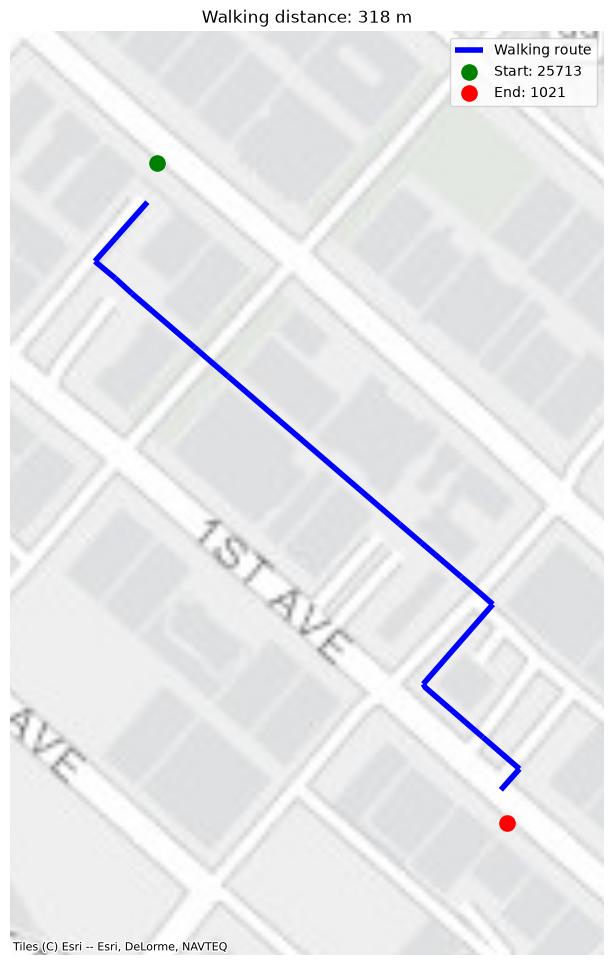

In [162]:
import matplotlib.pyplot as plt
import contextily as ctx
import networkx as nx
import osmnx as ox

origin_key, destination_key = 25713, 1021  # any two ELMNTKEY values from segments.index

street_graph_m = ox.project_graph(street_graph, to_crs='EPSG:32610')
pair_centers = segments.loc[[origin_key, destination_key]].geometry.centroid

route_nodes = nx.shortest_path(
    street_graph_m,
    *ox.distance.nearest_nodes(street_graph_m, X=pair_centers.x, Y=pair_centers.y),
    weight='length',
)
route_lines = ox.routing.route_to_gdf(street_graph_m, route_nodes)

fig, ax = plt.subplots(figsize=(12, 12))
route_lines.to_crs(epsg=3857).plot(ax=ax, color='blue', linewidth=4, label='Walking route')
pair_centers.iloc[[0]].to_crs(epsg=3857).plot(ax=ax, color='green', markersize=120, label=f'Start: {origin_key}', zorder=3)
pair_centers.iloc[[1]].to_crs(epsg=3857).plot(ax=ax, color='red', markersize=120, label=f'End: {destination_key}', zorder=3)

ax.margins(0.2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas)
ax.legend()
ax.set_axis_off()
ax.set_title(f"Walking distance: {segment_walking_m.loc[origin_key, destination_key]:.0f} m")
plt.show()

       straight_m  walking_m  difference_m  detour_ratio
count      378.00     378.00        378.00        378.00
mean       633.18     769.04        135.86          1.24
std        345.82     401.84         92.95          0.37
min         11.90       0.00        -21.50          0.00
25%        398.32     479.88         56.85          1.12
50%        607.75     742.20        113.75          1.19
75%        799.95    1010.62        220.60          1.33
max       1831.40    1978.90        378.20          7.28
pairs where walking is shorter than straight line: 4.2%


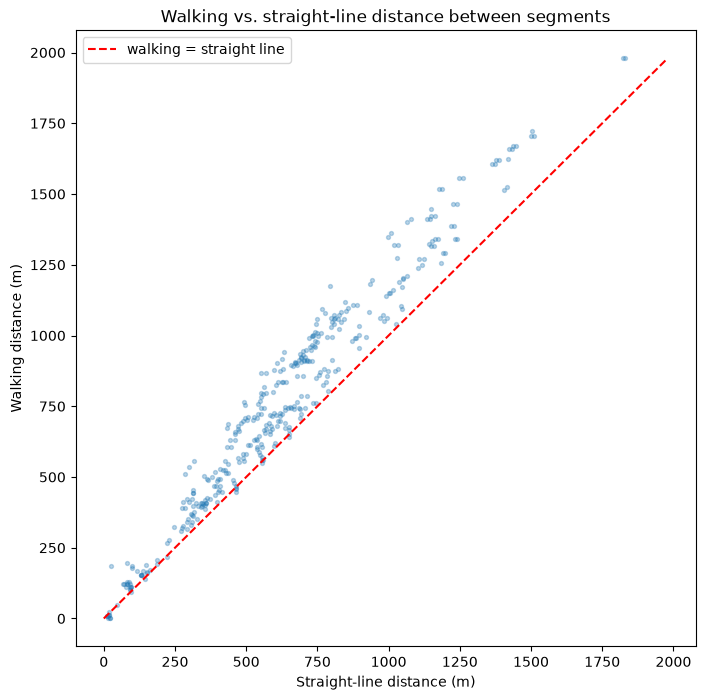

In [163]:
import numpy as np
import matplotlib.pyplot as plt

each_pair = np.triu(np.ones(segment_straight_m.shape, dtype=bool), k=1)

distance_comparison = pd.DataFrame({
    'straight_m': segment_straight_m.to_numpy()[each_pair],
    'walking_m': segment_walking_m.to_numpy()[each_pair],
})
distance_comparison['difference_m'] = distance_comparison['walking_m'] - distance_comparison['straight_m']
distance_comparison['detour_ratio'] = distance_comparison['walking_m'] / distance_comparison['straight_m'].replace(0, np.nan)

print(distance_comparison.describe().round(2))
print(f"pairs where walking is shorter than straight line: {(distance_comparison['difference_m'] < 0).mean():.1%}")

plt.figure(figsize=(8, 8))
plt.scatter(distance_comparison['straight_m'], distance_comparison['walking_m'], s=8, alpha=0.3)
longest_m = distance_comparison[['straight_m', 'walking_m']].max().max()
plt.plot([0, longest_m], [0, longest_m], color='red', linestyle='--', label='walking = straight line')
plt.xlabel('Straight-line distance (m)')
plt.ylabel('Walking distance (m)')
plt.title('Walking vs. straight-line distance between segments')
plt.legend()
plt.show()

In [164]:
import numpy as np

row_index, column_index = np.triu_indices(len(segments), k=1)

shorter_pairs = pd.DataFrame({
    'segment_a': segment_straight_m.index[row_index],
    'segment_b': segment_straight_m.columns[column_index],
    'straight_m': segment_straight_m.to_numpy()[row_index, column_index],
    'walking_m': segment_walking_m.to_numpy()[row_index, column_index],
}).assign(
    shorter_by_m=lambda table: table['straight_m'] - table['walking_m'],
    shorter_by_percent=lambda table: (table['shorter_by_m'] / table['straight_m'] * 100).round(1),
).query('shorter_by_m > 0').sort_values('shorter_by_m', ascending=False)

print(f"{len(shorter_pairs)} of {len(row_index)} pairs are shorter ({len(shorter_pairs) / len(row_index):.1%})")
print(shorter_pairs[['straight_m', 'walking_m', 'shorter_by_m', 'shorter_by_percent']].describe().round(1))

shorter_pairs.head(20)

16 of 378 pairs are shorter (4.2%)
       straight_m  walking_m  shorter_by_m  shorter_by_percent
count        16.0       16.0          16.0                16.0
mean        199.4      191.3           8.1                28.8
std         234.4      234.9           6.1                37.7
min          11.9        0.0           1.5                 0.9
25%          16.6        9.9           4.6                 1.6
50%          58.4       52.7           5.9                11.0
75%         463.3      451.2           9.4                35.4
max         650.9      642.9          21.5               100.0


,segment_a,segment_b,straight_m,walking_m,shorter_by_m,shorter_by_percent
242,53433,53434,21.5,0.0,21.5,100.0
357,76053,76054,20.1,0.0,20.1,100.0
30,1022,24046,463.8,448.6,15.2,3.3
273,57193,57194,13.5,0.0,13.5,100.0
44,1022,68921,650.9,642.9,8.0,1.2
43,1022,68918,556.9,549.0,7.9,1.4
189,28958,32434,145.8,139.6,6.2,4.3
102,24045,24046,16.8,10.9,5.9,35.1
0,1021,1022,16.2,10.3,5.9,36.4
323,68917,68918,17.4,11.5,5.9,33.9


In [165]:
gis_curb_idax_segments['SPACETYPE'].value_counts()

SPACETYPE
CVLZ       28
PLZ        16
PS-CVLZ    11
L/UL        8
PS-PLZ      2
CVLZ-P      2
PS-LUL      1
Name: count, dtype: int64

In [166]:
idax1_with_weather['SPACETYPE'].value_counts()

SPACETYPE
CVLZ       1389
PS-CVLZ     153
CVLZ/PS     148
L/UL        112
LOAD         58
PS-VEN       10
Name: count, dtype: int64